# RQ1 Final — Team Understanding from Early Learning-Process Transitions

**Frozen final RQ1 notebook | Approach 4: SPM + continuous-outcome Quade-type ANCOVA**

This notebook is the cleaned analysis/handoff version for RQ1. It preserves the revised Approach 4 logic:

- deterministic early-window selection by adjacent-window transition-direction ARI;
- `k = 3` baseline and selected optimum `k`;
- first `k` classified attempts as the early window;
- all attempts after `k` retained for the continuous later-percent-correct outcome;
- textbook contiguous SPM with **i-support = number of pattern instances / number of supporting histories**;
- SPM is **not stratified by early score**;
- continuous Quade-type ANCOVA adjusts for early score, scaffold share, item-type shares, mean early item easiness, and skill fixed effects;
- the 50% Later-Struggle threshold is used only for post-fit descriptive TNA/ΔP reporting;
- BH-FDR is applied across the 49 transition tests.

## RQ1 → RQ2/RQ3 handoff

The final section exports a **frozen RQ1 handoff object** containing the episode-level data and RQ1 analysis tables needed to start:

- **RQ2:** How does the early transition network change into the later window, and how does that change differ by Later-Struggle group?
- **RQ3:** Do early transition features add predictive value for later struggle beyond baseline correctness, assistance counts, BKT, and PFA?

The RQ2/RQ3 starter sections are intentionally scaffolds: they load the frozen handoff, construct the relevant early/later features, and mark the exact places where the final hypothesis/model specification should be inserted.


# Early Help-Seeking Transitions and Later Struggle in ASSISTments

## RQ1 — SPM (length 2…k) + Quade-type ANCOVA with continuous later performance

> **Which early help-seeking sequential patterns and transitions distinguish histories with lower later performance, after accounting for early score, scaffold exposure/item type, item easiness, and skill?**

This notebook uses two linked analyses:

1. **Sequential Pattern Mining (SPM):** for every pattern length `L = 2, 3, ..., k`, mine all contiguous patterns occurring inside the first `k` early states. For each pattern, compute the textbook **i-support** exactly as

\[
\boxed{\text{i-support} = \frac{\text{number of instances of pattern}}{\text{number of students/histories having the pattern}}}
\]

   Patterns are compared between the two later-performance groups with a two-sided Mann–Whitney U test on per-history occurrence counts, followed by BH-FDR. **Only FDR-significant patterns are reported as differential patterns.**

2. **Quade-type rank ANCOVA:** for the 49 possible length-2 transitions, fit the existing Approach 3 rank-based ANCOVA, but use **later percent correct as the outcome**, rather than the binary later-struggle label. The binary 50% threshold is **not used in model fitting**. After fitting, the 50% threshold is applied only to create the reporting classes used for TNA/ΔP plots.

### Eligibility

- Baseline: `k = 3` early attempts + at least 3 later attempts.
- For each candidate `k`, eligibility is `n_attempts >= 2k`.
- The first `k` classified attempts are the early window.
- All attempts after the first `k` contribute to later percent correct.
- The optimum `k` is selected using the same deterministic adjacent-window ARI criterion as before.

### Important distinction about ties

The Quade model is fitted to **continuous later percent correct**, so it does not create the massive ties induced by a binary 0/1 outcome. Exact equal percentage values can still legitimately receive tied midranks; those ties are a property of the observed continuous/discrete percentage data and are not removed by artificial jittering.

For reporting/plots only, after model fitting:

\[
\text{Later Struggle class} = \mathbf{1}(\text{later percent correct}<50\%).
\]

Thus the inferential model and the plotted outcome class are explicitly separated.

### What is reported

- SPM: only patterns with BH-FDR `< .05`, for lengths 2 through `k`.
- For each significant pattern: length, pattern, group-wise instances, supporting histories, textbook i-support, s-support, MWU p-value, and FDR p-value.
- Quade ANCOVA: all 49 transitions are tested; significant transitions are retained after BH-FDR.
- ΔP and transition-probability plots use the **post-fit 50% reporting class**, not the outcome used in the Quade model.


## 1. Imports, paths, and frozen settings


In [1]:
import os
import random
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.lines import Line2D

import statsmodels.api as sm
from scipy.stats import rankdata, mannwhitneyu
from sklearn.metrics import adjusted_rand_score

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "rq1_merged_spm_quade_outputs"
PLOTS_DIR = DATA_DIR / "plots_quade_ancova"
DATA_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = BASE_DIR / "assistments-p(j)-data.zip"
if not ZIP_PATH.exists():
    candidates = sorted(BASE_DIR.glob("assistments-p(j)-data*.zip"))
    if not candidates:
        raise FileNotFoundError("Could not find assistments-p(j)-data*.zip")
    ZIP_PATH = candidates[0]

STATE_ORDER = [
    "CFA", "ERR-SELF", "BOH", "SCAF-STRUGGLE",
    "ERR-HINT", "HINT-FIRST", "SCAF-PASS"
]
OUTCOME_LABELS = {0: "No Later Struggle", 1: "Later Struggle"}

# All 7 × 7 directed transitions among the frozen help-seeking states.
ALL_TRANSITIONS = [
    f"{s1} → {s2}"
    for s1 in STATE_ORDER
    for s2 in STATE_ORDER
]
assert len(ALL_TRANSITIONS) == 49
ALPHA = 0.05

K_BASELINE = 3
K_MIN = 3
K_MAX = 10

print("ZIP:", ZIP_PATH)
print("Baseline k:", K_BASELINE)
print("Baseline minimum later attempts:", K_BASELINE)
print("Baseline minimum history:", 2 * K_BASELINE)
print("Random seed:", RANDOM_SEED)


ZIP: c:\Users\Gaurish\Desktop\ET Folder IITB Synced\ET IITB\ET Sem 1\Learning Analytics\project\Code_Final_RQ1_to_be_used\assistments-p(j)-data.zip
Baseline k: 3
Baseline minimum later attempts: 3
Baseline minimum history: 6
Random seed: 42


## 2. Helper functions


In [2]:
def bh_fdr(p_values):
    """Benjamini–Hochberg FDR correction, preserving NaNs."""
    p = pd.Series(p_values, dtype=float)
    out = pd.Series(np.nan, index=p.index, dtype=float)
    valid = p.notna()
    if not valid.any():
        return out.to_numpy()

    pv = p.loc[valid].to_numpy()
    order = np.argsort(pv, kind="mergesort")
    ranked = pv[order]
    m = len(ranked)

    adjusted = ranked * m / np.arange(1, m + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)

    restored = np.empty_like(adjusted)
    restored[order] = adjusted
    out.loc[valid] = restored
    return out.to_numpy()


def make_delta(transitions):
    """Return No-Struggle TNA, Later-Struggle TNA, and ΔP.

    ΔP = P(transition | Later Struggle)
         - P(transition | No Later Struggle).

    Transition probabilities are row-normalized by source state.
    """
    matrices = {}
    for outcome in [0, 1]:
        sub = transitions.loc[
            transitions["later_struggle"].eq(outcome)
        ].copy()

        counts = (
            sub.groupby(["state", "next_state"])
            .size()
            .unstack(fill_value=0)
            .reindex(index=STATE_ORDER, columns=STATE_ORDER, fill_value=0)
        )
        row_totals = counts.sum(axis=1)
        matrices[outcome] = counts.div(
            row_totals.replace(0, np.nan),
            axis=0
        )

    tna0 = matrices[0]
    tna1 = matrices[1]
    delta = tna1 - tna0
    return delta, tna0, tna1


def build_population(episodes, k, min_total_attempts=None):
    """Build an RQ1 population using k early attempts and at least k later attempts.

    Eligibility requires k early + at least k later classified attempts,
    i.e. n_attempts >= 2*k. All attempts after the first k are retained
    in the later window and contribute to the later-struggle outcome.
    """
    base = episodes.sort_values(
        ["userId", "skill", "start_time", "episode_row_order"],
        kind="mergesort"
    ).copy()
    base["skill_attempt"] = base.groupby(["userId", "skill"]).cumcount() + 1

    lengths = (
        base.groupby(["userId", "skill"])
        .size()
        .rename("n_attempts")
        .reset_index()
    )

    required_total = 2 * k
    if min_total_attempts is None:
        min_total_attempts = required_total
    if min_total_attempts < required_total:
        raise ValueError(
            f"min_total_attempts must be at least {required_total} for k={k}."
        )

    eligible = lengths.loc[lengths["n_attempts"] >= min_total_attempts].copy()
    base = base.merge(eligible, on=["userId", "skill"], how="inner")

    # First k = early; every classified attempt after the early window = later.
    base["window"] = np.where(
        base["skill_attempt"] <= k,
        "early",
        "later"
    )

    early = base.loc[base.window.eq("early")].copy()
    later = base.loc[base.window.eq("later")].copy()

    later_outcome = later.groupby(["userId", "skill"], as_index=False).agg(
        later_percent_correct=("first_correct", lambda x: 100.0 * x.mean()),
        n_later_attempts=("first_correct", "size")
    )
    later_outcome["later_first_correct_rate"] = later_outcome["later_percent_correct"] / 100.0
    later_outcome["later_struggle"] = (
        later_outcome.later_percent_correct < 50.0
    ).astype(int)

    population = eligible.merge(
        later_outcome,
        on=["userId", "skill"],
        how="inner"
    )

    early = early.merge(problem_easiness, on="problemId", how="left")
    cov = early.groupby(["userId", "skill"], as_index=False).agg(
        early_score=("first_correct", "sum"),
        early_scaffold_share=("any_scaffold", "mean"),
        mean_early_item_easiness=("item_easiness", "mean"),
        early_algebra_share=("problemType", lambda x: (x == "algebra").mean()),
        early_choose_1_share=("problemType", lambda x: (x == "choose_1").mean()),
        early_fill_in_1_share=("problemType", lambda x: (x == "fill_in_1").mean())
    )
    population = population.merge(cov, on=["userId", "skill"], how="left")

    early = early.sort_values(
        ["userId", "skill", "start_time", "episode_row_order"],
        kind="mergesort"
    ).copy()
    early["next_state"] = early.groupby(["userId", "skill"])["state"].shift(-1)

    transitions = early.loc[
        early.next_state.notna(),
        ["userId", "skill", "skill_attempt", "state", "next_state"]
    ].copy()
    transitions = transitions.merge(
        population[["userId", "skill", "later_struggle"]],
        on=["userId", "skill"],
        how="inner"
    )
    transitions["transition"] = (
        transitions.state.astype(str) + " → " +
        transitions.next_state.astype(str)
    )

    transition_counts = (
        transitions.pivot_table(
            index=["userId", "skill"],
            columns="transition",
            values="state",
            aggfunc="size",
            fill_value=0
        )
        .reindex(columns=ALL_TRANSITIONS, fill_value=0)
        .reset_index()
        .merge(
            population[["userId", "skill", "later_struggle"]],
            on=["userId", "skill"],
            how="left"
        )
    )

    return {
        "base": base,
        "early": early,
        "later": later,
        "population": population,
        "transitions": transitions,
        "transition_counts": transition_counts
    }


# Fixed state colors and identical layout for the two outcome networks.
STATE_COLORS = {
    "CFA": "#4CAF50",
    "ERR-SELF": "#2196F3",
    "BOH": "#F44336",
    "SCAF-STRUGGLE": "#FF9800",
    "ERR-HINT": "#9C27B0",
    "HINT-FIRST": "#00ACC1",
    "SCAF-PASS": "#8BC34A"
}

def plot_single_tna_network(
    mat, outcome, selected_k, threshold=0.01, filename=None
):
    """Plot a directed early-TNA network with explicit arrowheads.

    Edge direction is FROM the source state TO the next state.
    Self-transitions are drawn as curved self-loop arrows so their
    direction remains visually explicit.
    """
    G = nx.DiGraph()
    G.add_nodes_from(STATE_ORDER)

    for from_state in STATE_ORDER:
        for to_state in STATE_ORDER:
            value = mat.loc[from_state, to_state]
            if pd.notna(value) and value >= threshold:
                G.add_edge(from_state, to_state, weight=float(value))

    base_graph = nx.DiGraph()
    base_graph.add_nodes_from(STATE_ORDER)
    pos = nx.circular_layout(base_graph)

    fig, ax = plt.subplots(figsize=(13, 11))

    nx.draw_networkx_nodes(
        G, pos, ax=ax, nodelist=STATE_ORDER,
        node_color=[STATE_COLORS[s] for s in STATE_ORDER],
        node_size=3000, edgecolors="black", linewidths=1.5
    )
    nx.draw_networkx_labels(
        G, pos, ax=ax, font_size=9, font_weight="bold"
    )

    non_self_edges = [(u, v) for u, v in G.edges() if u != v]
    self_edges = [(u, v) for u, v in G.edges() if u == v]

    # Directed transitions between different states.
    if non_self_edges:
        widths = [1 + 6 * G[u][v]["weight"] for u, v in non_self_edges]
        nx.draw_networkx_edges(
            G, pos, ax=ax, edgelist=non_self_edges,
            width=widths,
            arrows=True,
            arrowstyle="-|>",
            arrowsize=24,
            min_source_margin=18,
            min_target_margin=22,
            connectionstyle="arc3,rad=0.10",
            alpha=0.78
        )

    # Explicit curved self-loop arrows.
    for u, v in self_edges:
        width = 1 + 6 * G[u][v]["weight"]
        x, y = pos[u]
        ax.annotate(
            "",
            xy=(x + 0.10, y + 0.02),
            xytext=(x - 0.10, y + 0.02),
            arrowprops=dict(
                arrowstyle="-|>",
                mutation_scale=24,
                linewidth=width,
                connectionstyle="arc3,rad=-2.0",
                shrinkA=0,
                shrinkB=0
            )
        )

    edge_labels = {
        (u, v): f"{G[u][v]['weight']:.2f}"
        for u, v in G.edges()
    }
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels=edge_labels,
        ax=ax, font_size=8, label_pos=0.5, rotate=False
    )

    legend_handles = [
        Line2D(
            [0], [0], marker="o", color="w", label=state,
            markerfacecolor=STATE_COLORS[state],
            markeredgecolor="black", markersize=11
        )
        for state in STATE_ORDER
    ]
    ax.legend(
        handles=legend_handles, title="Help-Seeking State",
        loc="upper left", bbox_to_anchor=(1.02, 1),
        frameon=True, fontsize=9, title_fontsize=10
    )

    ax.set_title(
        f"{OUTCOME_LABELS[outcome]} — Directed Early TNA (k={selected_k})",
        fontsize=15, fontweight="bold"
    )
    ax.text(
        0.5, -0.03,
        "Arrow direction: source state → next state; edge label = transition probability",
        transform=ax.transAxes, ha="center", va="top", fontsize=9
    )
    ax.axis("off")
    fig.tight_layout()

    if filename is None:
        filename = (
            f"k{selected_k}_"
            f"{'no_later_struggle' if outcome == 0 else 'later_struggle'}"
            "_tna_network.png"
        )

    fig.savefig(PLOTS_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    return G


## 3. Load raw ASSISTments action data


In [3]:
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    df = pd.read_csv(z.open("PJ Data (Actions).csv"))

df["_raw_row_order"] = np.arange(len(df), dtype=np.int64)
df["startTime"] = pd.to_datetime(df["startTime"], errors="coerce")

print("Raw shape:", df.shape)
print("Students:", df["userId"].nunique())
print("Skills:", df["skill"].nunique())
print("Problem IDs:", df["problemId"].nunique())
print("Problem types:", sorted(df["problemType"].dropna().astype(str).unique().tolist()))


Raw shape: (413428, 18)
Students: 4140
Skills: 55
Problem IDs: 12142
Problem types: ['algebra', 'choose_1', 'fill_in_1', 'open_response']


## 4. Construct main-problem episodes and frozen seven-state labels


In [4]:
df = df.sort_values(
    ["userId", "skill", "startTime", "problemId", "attemptCount", "_raw_row_order"],
    kind="mergesort"
).copy()

main_rows = df[df["original"] == 1].copy()
episode = (
    main_rows.groupby(
        ["userId", "assistmentId", "problemId", "skill"], as_index=False
    ).agg(
        n_actions=("problemId", "size"),
        first_correct=("correct", "first"),
        last_correct=("correct", "last"),
        any_correct=("correct", "max"),
        any_hint=("hint", "max"),
        any_bottom_hint=("bottomHint", "max"),
        any_scaffold=("scaffold", "max"),
        first_hint=("hint", "first"),
        first_bottom_hint=("bottomHint", "first"),
        first_scaffold=("scaffold", "first"),
        max_attempt=("attemptCount", "max"),
        start_time=("startTime", "first"),
        problemType=("problemType", "first"),
        episode_row_order=("_raw_row_order", "first")
    )
)

scaffold_episodes = episode.loc[
    episode["any_scaffold"].eq(1), ["userId", "assistmentId"]
].drop_duplicates()
scaffold_subq = df[df["original"].eq(0)].merge(
    scaffold_episodes, on=["userId", "assistmentId"], how="inner"
)
subq_first = (
    scaffold_subq.sort_values(
        ["userId", "assistmentId", "problemId", "attemptCount", "_raw_row_order"],
        kind="mergesort"
    ).groupby(["userId", "assistmentId", "problemId"], as_index=False).first()
)
scaffold_outcome = (
    subq_first.groupby(["userId", "assistmentId"], as_index=False)
    .agg(
        n_subquestions=("problemId", "nunique"),
        n_first_attempt_correct=("correct", "sum")
    )
)
scaffold_outcome["scaf_state"] = np.where(
    scaffold_outcome["n_subquestions"] == scaffold_outcome["n_first_attempt_correct"],
    "SCAF-PASS", "SCAF-STRUGGLE"
)
episode = episode.merge(
    scaffold_outcome[["userId", "assistmentId", "scaf_state"]],
    on=["userId", "assistmentId"], how="left"
)

episode["state"] = pd.Series(pd.NA, index=episode.index, dtype="string")
mask = episode["any_scaffold"].eq(1) & episode["scaf_state"].eq("SCAF-PASS")
episode.loc[mask, "state"] = "SCAF-PASS"
mask = episode["any_scaffold"].eq(1) & (
    episode["scaf_state"].eq("SCAF-STRUGGLE") | episode["scaf_state"].isna()
)
episode.loc[mask, "state"] = "SCAF-STRUGGLE"
mask = episode["state"].isna() & episode["any_bottom_hint"].eq(1)
episode.loc[mask, "state"] = "BOH"
mask = episode["state"].isna() & episode["first_hint"].eq(1)
episode.loc[mask, "state"] = "HINT-FIRST"
mask = (
    episode["state"].isna() & episode["first_correct"].eq(0)
    & episode["any_hint"].eq(1) & episode["any_bottom_hint"].eq(0)
    & episode["last_correct"].eq(1)
)
episode.loc[mask, "state"] = "ERR-HINT"
mask = (
    episode["state"].isna() & episode["first_correct"].eq(0)
    & episode["last_correct"].eq(1) & episode["any_hint"].eq(0)
    & episode["any_bottom_hint"].eq(0) & episode["any_scaffold"].eq(0)
)
episode.loc[mask, "state"] = "ERR-SELF"
mask = (
    episode["state"].isna() & episode["first_correct"].eq(1)
    & episode["any_hint"].eq(0) & episode["any_bottom_hint"].eq(0)
    & episode["any_scaffold"].eq(0)
)
episode.loc[mask, "state"] = "CFA"

problem_easiness = (
    episode.groupby("problemId", as_index=False)
    .agg(item_easiness=("first_correct", "mean"))
)

episode = episode.loc[episode["state"].notna()].copy()
episode = episode.sort_values(
    ["userId", "skill", "start_time", "episode_row_order"], kind="mergesort"
).reset_index(drop=True)

print("Classified episodes:", len(episode))
display(episode["state"].value_counts().reindex(STATE_ORDER).rename("count").to_frame())


Classified episodes: 163800


,count
state,
CFA,109738
ERR-SELF,18510
BOH,16746
SCAF-STRUGGLE,5866
ERR-HINT,4831
HINT-FIRST,4314
SCAF-PASS,3795


## 5. k = 3 baseline analysis — 3 early + 6 later classified attempts


In [5]:
# All possible directed transitions among the frozen states
ALL_TRANSITIONS = [
    f"{s1} → {s2}"
    for s1 in STATE_ORDER
    for s2 in STATE_ORDER
]

k3 = build_population(episode, 3, min_total_attempts=2 * 3)
analysis_k3 = k3["population"]
transitions_k3 = k3["transitions"]
counts_k3 = k3["transition_counts"]

a = analysis_k3
print("Eligible student × skill histories:", len(a))
print("No Later Struggle:", int((a.later_struggle == 0).sum()))
print("Later Struggle:", int((a.later_struggle == 1).sum()))
print("Mean later percent correct:", round(a.later_percent_correct.mean(), 2))
print("Reporting-class later-struggle rate (<50%):", round(100 * (a.later_percent_correct < 50).mean(), 2), "%")
print("Minimum history length:", int(a.n_attempts.min()))
print("Minimum later attempts:", int(a.n_later_attempts.min()))
assert a.n_attempts.min() >= 6
assert a.n_later_attempts.min() >= 3
assert a.early_score.between(0, 3).all()


Eligible student × skill histories: 9980
No Later Struggle: 8190
Later Struggle: 1790
Mean later percent correct: 72.41
Reporting-class later-struggle rate (<50%): 17.94 %
Minimum history length: 6
Minimum later attempts: 3


## 6. k = 3 group-wise TNA and descriptive ΔP


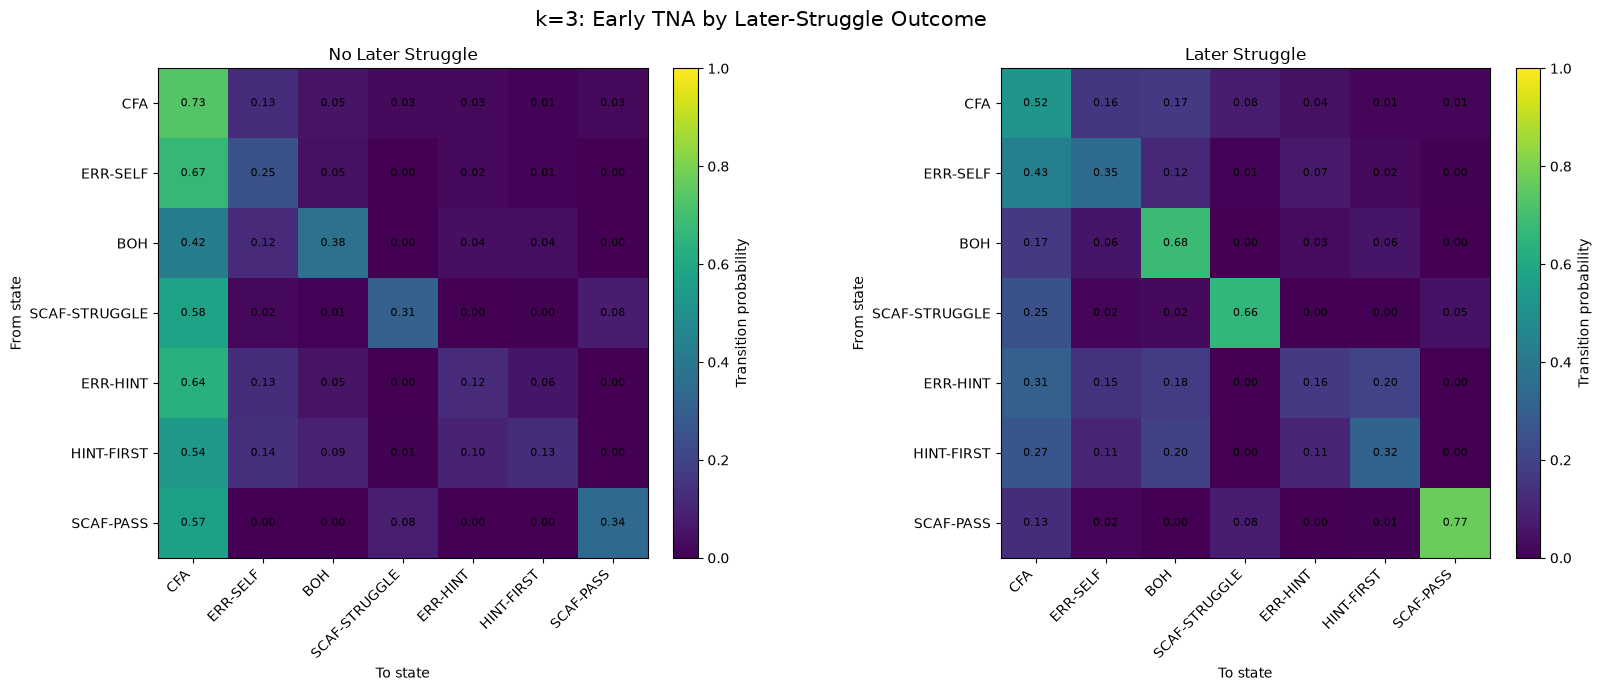

k=3 observed maximum |ΔP|: 0.4412


In [6]:
delta_k3, tna0_k3, tna1_k3 = make_delta(transitions_k3)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, outcome, mat in zip(axes, [0, 1], [tna0_k3, tna1_k3]):
    im = ax.imshow(mat.to_numpy(), vmin=0, vmax=1)
    ax.set_title(OUTCOME_LABELS[outcome])
    ax.set_xticks(range(len(STATE_ORDER)), STATE_ORDER, rotation=45, ha="right")
    ax.set_yticks(range(len(STATE_ORDER)), STATE_ORDER)
    ax.set_xlabel("To state")
    ax.set_ylabel("From state")
    for i in range(len(STATE_ORDER)):
        for j in range(len(STATE_ORDER)):
            v = mat.iloc[i, j]
            if pd.notna(v): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Transition probability")
fig.suptitle("k=3: Early TNA by Later-Struggle Outcome", fontsize=15)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "k3_tna_groupwise.png", dpi=300, bbox_inches="tight")
plt.show()

print("k=3 observed maximum |ΔP|:", round(np.nanmax(np.abs(delta_k3.to_numpy())), 4))


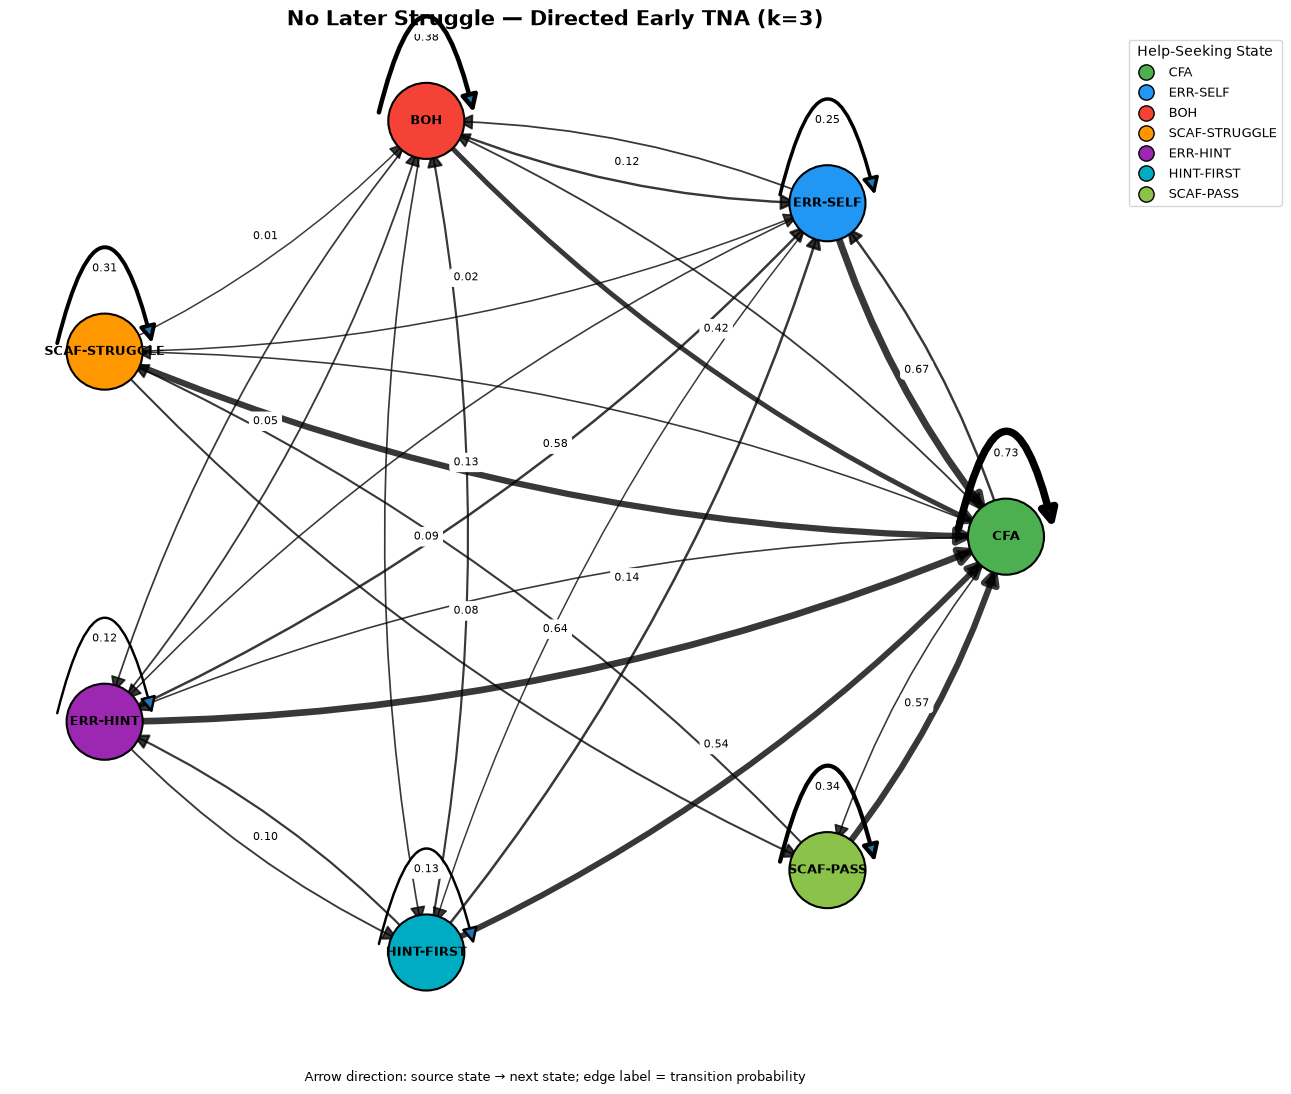

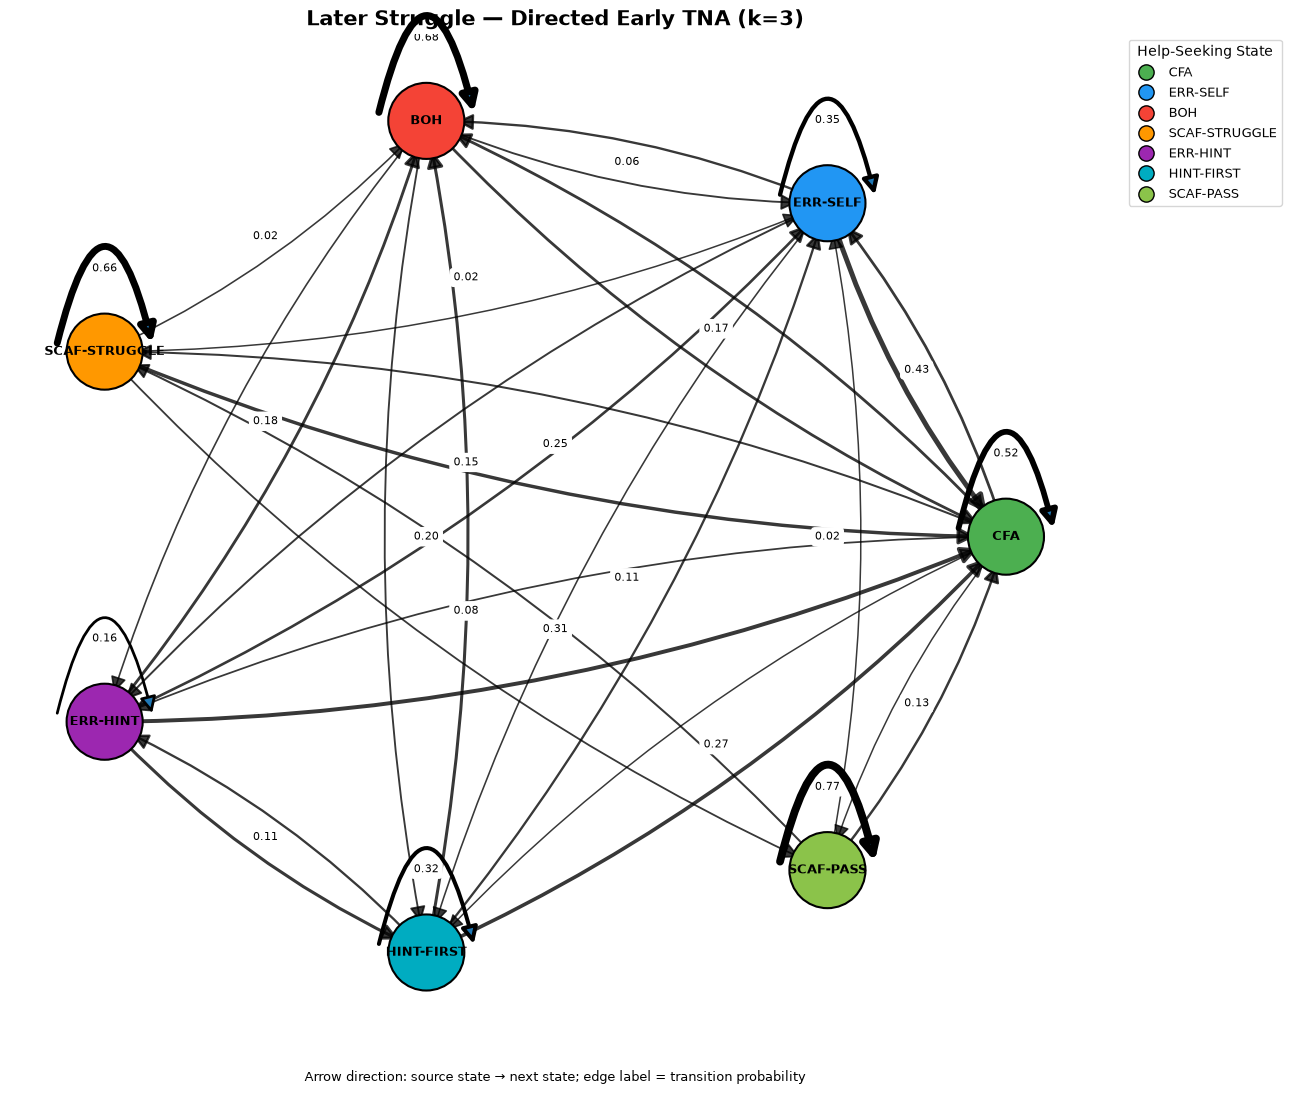

In [7]:
# k=3: separate TNA network figures
G_k3_no_struggle = plot_single_tna_network(
    tna0_k3,
    outcome=0,
    selected_k=3,
    threshold=0.01,
    filename="k3_no_later_struggle_tna_network.png"
)

G_k3_struggle = plot_single_tna_network(
    tna1_k3,
    outcome=1,
    selected_k=3,
    threshold=0.01,
    filename="k3_later_struggle_tna_network.png"
)


In [8]:
TOP_N_PATTERNS = 20


def mine_spm_2_to_k(population_bundle, k, top_n=TOP_N_PATTERNS):
    """Mine contiguous patterns of every length L=2,...,k in the first k states.

    Textbook i-support:
        i-support(pattern) = total number of pattern instances /
                             number of student x skill histories containing pattern.

    A history may contain the same pattern multiple times because patterns shorter
    than the early window are mined with a sliding window. The per-history count
    is therefore the number of occurrences used for the DSM/MWU comparison.
    """
    population = population_bundle["population"].copy()
    early = population_bundle["early"].copy()
    early = early.sort_values(
        ["userId", "skill", "skill_attempt", "start_time", "episode_row_order"],
        kind="mergesort"
    )

    sequences = (
        early.groupby(["userId", "skill"], sort=False)["state"]
        .agg(lambda x: tuple(x.astype(str).tolist()))
        .rename("sequence_tuple")
        .reset_index()
    )
    assert sequences["sequence_tuple"].map(len).eq(k).all()

    hist_base = population[["userId", "skill", "later_percent_correct"]].copy()
    hist_base = hist_base.merge(sequences, on=["userId", "skill"], how="inner")

    # Build per-history occurrence counts for every observed contiguous pattern
    # of every length 2..k.
    records = []
    for row in hist_base.itertuples(index=False):
        seq = row.sequence_tuple
        for L in range(2, k + 1):
            for start in range(0, k - L + 1):
                pattern_tuple = seq[start:start + L]
                records.append({
                    "userId": row.userId,
                    "skill": row.skill,
                    "later_percent_correct": row.later_percent_correct,
                    "pattern_length": L,
                    "pattern": " → ".join(pattern_tuple)
                })

    instances = pd.DataFrame(records)
    if instances.empty:
        raise ValueError("No SPM instances were generated.")

    per_history = (
        instances.groupby(
            ["userId", "skill", "later_percent_correct", "pattern_length", "pattern"],
            as_index=False
        ).size()
        .rename(columns={"size": "i_support_per_history"})
    )

    # Reporting groups are created from later percent correct only for the SPM
    # comparison. The threshold is not used by the Quade model.
    per_history["plot_class"] = np.where(
        per_history["later_percent_correct"] < 50.0,
        1, 0
    )
    per_history["plot_class_label"] = per_history["plot_class"].map(OUTCOME_LABELS)

    rows = []
    for (L, pattern), gpat in per_history.groupby(["pattern_length", "pattern"], sort=True):
        x = gpat.loc[gpat.plot_class.eq(0), "i_support_per_history"].to_numpy(dtype=float)
        y = gpat.loc[gpat.plot_class.eq(1), "i_support_per_history"].to_numpy(dtype=float)
        if len(x) == 0 or len(y) == 0:
            p = np.nan
            u = np.nan
        else:
            u, p = mannwhitneyu(x, y, alternative="two-sided", method="auto")

        row = {
            "pattern_length": int(L),
            "pattern": pattern,
            "n_instances_NS": int(x.sum()),
            "n_supporting_histories_NS": int((x > 0).sum()),
            "i_support_NS": float(x.sum() / (x > 0).sum()) if (x > 0).sum() else np.nan,
            "s_support_NS": float((x > 0).mean()) if len(x) else np.nan,
            "mean_i_support_per_history_NS": float(x.mean()) if len(x) else np.nan,
            "n_instances_S": int(y.sum()),
            "n_supporting_histories_S": int((y > 0).sum()),
            "i_support_S": float(y.sum() / (y > 0).sum()) if (y > 0).sum() else np.nan,
            "s_support_S": float((y > 0).mean()) if len(y) else np.nan,
            "mean_i_support_per_history_S": float(y.mean()) if len(y) else np.nan,
            "mwu_U": float(u) if np.isfinite(u) else np.nan,
            "p_value": float(p) if np.isfinite(p) else np.nan,
            "n_histories_NS": int(len(x)),
            "n_histories_S": int(len(y)),
            "k": int(k)
        }
        rows.append(row)

    results = pd.DataFrame(rows)
    results["fdr_p"] = bh_fdr(results["p_value"])
    results["significant"] = results["fdr_p"] < ALPHA
    results["direction"] = np.where(
        results["mean_i_support_per_history_S"] > results["mean_i_support_per_history_NS"],
        "More instances in Later Struggle",
        np.where(
            results["mean_i_support_per_history_S"] < results["mean_i_support_per_history_NS"],
            "More instances in No Later Struggle",
            "Equal"
        )
    )

    # Only significantly different patterns are reported downstream.
    significant = results.loc[results["significant"]].copy()
    significant = significant.sort_values(
        ["fdr_p", "p_value", "pattern_length", "pattern"],
        kind="mergesort"
    ).reset_index(drop=True)

    # IMPORTANT: SPM is not stratified by early score.
    # Early score is reserved for the downstream Quade-type ANCOVA as a
    # continuous covariate. SPM significance is assessed across the two
    # later-performance outcome groups only.
    return {
        "per_history": per_history,
        "all_patterns": results,
        "significant_patterns": significant,
    }


## 7. SPM-style mining of full length-`k` early sequences — textbook i-support

The SPM stage uses the **entire early window as the pattern length** and applies the requested textbook definition exactly:

\[
\boxed{\text{i-support} = \frac{\text{number of instances of pattern}}{\text{number of students/histories having the pattern}}}
\]

For each outcome group and each complete length-`k` pattern, the notebook reports:

- **total instances**: number of occurrences of that pattern in the early sequences;
- **number of supporting histories**: number of student × skill histories containing the pattern;
- **i-support**: `total_instances / n_supporting_histories`;
- **s-support**: `n_supporting_histories / number of histories in the outcome group`.

Because the mined pattern length is exactly the early-window length `k`, a history can contain only one such complete pattern. Consequently, every observed full-length-`k` pattern has i-support = 1.0. This is a mathematical consequence of the chosen window/pattern definition, not a different definition of i-support.

The SPM stage is **descriptive**: it identifies the most common full early sequences, including within outcome × early-score strata. It does not screen the subsequent Quade analysis.


In [9]:
spm_k3 = mine_spm_2_to_k(k3, 3)

print("=" * 80)
print("SPM — PATTERN LENGTHS 2 TO k=3 — TEXTBOOK i-SUPPORT")
print("=" * 80)
print("Total candidate patterns:", len(spm_k3["all_patterns"]))
print("FDR-significant patterns:", int(spm_k3["significant_patterns"].shape[0]))
print("\nOnly FDR-significant differential patterns are reported:")
display(spm_k3["significant_patterns"].round(4))


SPM — PATTERN LENGTHS 2 TO k=3 — TEXTBOOK i-SUPPORT
Total candidate patterns: 244
FDR-significant patterns: 4

Only FDR-significant differential patterns are reported:


,pattern_length,pattern,n_instances_NS,n_supporting_histories_NS,i_support_NS,s_support_NS,mean_i_support_per_history_NS,n_instances_S,n_supporting_histories_S,i_support_S,s_support_S,mean_i_support_per_history_S,mwu_U,p_value,n_histories_NS,n_histories_S,k,fdr_p,significant,direction
0,2,BOH → BOH,691,509,1.3576,1.0,1.3576,871,517,1.6847,1.0,1.6847,88530.5,0.0000,509,517,3,0.0000,True,More instances in Later Struggle
1,2,CFA → CFA,6999,4591,1.5245,1.0,1.5245,479,380,1.2605,1.0,1.2605,1102555.5,0.0000,4591,380,3,0.0000,True,More instances in No Later Struggle
2,2,SCAF-PASS → SCAF-PASS,221,154,1.4351,1.0,1.4351,150,83,1.8072,1.0,1.8072,4012.5,0.0000,154,83,3,0.0000,True,More instances in Later Struggle
3,2,SCAF-STRUGGLE → SCAF-STRUGGLE,234,174,1.3448,1.0,1.3448,212,137,1.5474,1.0,1.5474,9504.0,0.0004,174,137,3,0.0006,True,More instances in Later Struggle


## 8. Approach 4 — Quade-type ANCOVA for k = 3 (continuous later percent correct)

For each of the 49 transitions, fit the same Quade-type rank ANCOVA framework, but change the dependent variable from the binary `later_struggle` label to **later percent correct**.

- Outcome: `later_percent_correct` across **all attempts after the first k**.
- Focal factor: presence/absence of each length-2 transition in the first `k` attempts.
- Continuous covariates: `early_score`, `early_scaffold_share`, `mean_early_item_easiness`, and early item-type shares.
- Skill: fixed-effect nuisance terms.
- Continuous outcome and continuous nuisance variables are midranked.
- The focal transition is tested with the same partial ANCOVA F-test.
- BH-FDR is applied across the 49 transition-specific tests.

The 50% later-struggle threshold is **not used in fitting this model**. After model fitting, it is used only to create the two reporting classes for TNA/ΔP plots.


In [10]:
def _midrank(x):
    return rankdata(np.asarray(x, dtype=float), method="average")


def fit_quade_ancova_continuous(population, transition_counts, k, states=STATE_ORDER):
    """Fit the Approach-4 Quade-type rank ANCOVA using continuous later percent correct.

    The binary later-struggle threshold is deliberately excluded from model fitting; it is used only for post-fit descriptive reporting.
    Exact equal percentage values can still receive legitimate average midranks.
    """
    cov_cols = [
        "early_score", "early_scaffold_share", "mean_early_item_easiness",
        "early_algebra_share", "early_choose_1_share", "early_fill_in_1_share"
    ]

    model_df = transition_counts[["userId", "skill"] + ALL_TRANSITIONS].merge(
        population[["userId", "skill", "later_percent_correct"] + cov_cols],
        on=["userId", "skill"], how="inner"
    ).copy()
    model_df = model_df.dropna(subset=cov_cols + ["later_percent_correct", "skill"]).copy()
    model_df["skill"] = model_df["skill"].astype(str)

    ranked_y = _midrank(model_df["later_percent_correct"].to_numpy())
    ranked_cov = pd.DataFrame(index=model_df.index)
    for col in cov_cols:
        ranked_cov[col] = _midrank(model_df[col].to_numpy())

    skill_dummies = pd.get_dummies(model_df["skill"], prefix="skill", drop_first=True, dtype=float)
    nuisance = pd.concat([ranked_cov, skill_dummies], axis=1).astype(float)
    nuisance = sm.add_constant(nuisance, has_constant="add")
    reduced_fit = sm.OLS(ranked_y, nuisance).fit()

    rows, failures = [], []
    for tr in ALL_TRANSITIONS:
        try:
            group = (model_df[tr].to_numpy(dtype=float) > 0).astype(float)
            if np.unique(group).size < 2:
                raise ValueError("Transition has no variation.")
            full_X = nuisance.copy()
            full_X["transition"] = group
            full_fit = sm.OLS(ranked_y, full_X).fit()
            f_stat, p_value, df_diff = full_fit.compare_f_test(reduced_fit)
            rows.append({
                "transition": tr,
                "adjusted_rank_effect": float(full_fit.params["transition"]),
                "f_statistic": float(f_stat),
                "df_num": int(df_diff),
                "df_den": float(full_fit.df_resid),
                "p_value": float(p_value),
                "n": len(model_df),
                "model_converged": True
            })
        except Exception as exc:
            failures.append({"transition": tr, "error": repr(exc)})
            rows.append({
                "transition": tr, "adjusted_rank_effect": np.nan,
                "f_statistic": np.nan, "df_num": np.nan, "df_den": np.nan,
                "p_value": np.nan, "n": len(model_df), "model_converged": False
            })

    results = pd.DataFrame(rows)
    results["fdr_p"] = bh_fdr(results["p_value"])
    results["significant"] = results["fdr_p"] < ALPHA
    results["k"] = k
    results["direction"] = np.where(
        results["adjusted_rank_effect"] > 0,
        "Higher later percent correct",
        np.where(results["adjusted_rank_effect"] < 0,
                 "Lower later percent correct", "Equal")
    )
    return results.sort_values(["fdr_p", "p_value"], na_position="last").reset_index(drop=True), failures, model_df


model_k3, failures_k3, model_frame_k3 = fit_quade_ancova_continuous(
    analysis_k3, counts_k3, 3
)

print("k=3 continuous-outcome Quade ANCOVA model failures:", len(failures_k3))
print("k=3 FDR-significant transitions:", int(model_k3.significant.sum()))
display(model_k3.round(5))
if failures_k3:
    display(pd.DataFrame(failures_k3))


k=3 continuous-outcome Quade ANCOVA model failures: 3
k=3 FDR-significant transitions: 16


,transition,adjusted_rank_effect,f_statistic,df_num,df_den,p_value,n,model_converged,fdr_p,significant,k,direction
0,BOH → BOH,-1235.99288,178.76435,1.0,9921.0,0.00000,9980,True,0.00000,True,3,Lower later percent correct
1,CFA → ERR-SELF,838.97641,132.39204,1.0,9921.0,0.00000,9980,True,0.00000,True,3,Higher later percent correct
2,ERR-SELF → CFA,680.82977,107.13659,1.0,9921.0,0.00000,9980,True,0.00000,True,3,Higher later percent correct
3,ERR-SELF → ERR-SELF,918.73993,70.62194,1.0,9921.0,0.00000,9980,True,0.00000,True,3,Higher later percent correct
4,SCAF-STRUGGLE → SCAF-STRUGGLE,-1018.90797,37.55535,1.0,9921.0,0.00000,9980,True,0.00000,True,3,Lower later percent correct
5,CFA → SCAF-PASS,983.42471,34.16028,1.0,9921.0,0.00000,9980,True,0.00000,True,3,Higher later percent correct
6,CFA → CFA,-466.57788,29.77915,1.0,9921.0,0.00000,9980,True,0.00000,True,3,Lower later percent correct
7,SCAF-PASS → CFA,734.86351,26.57497,1.0,9921.0,0.00000,9980,True,0.00000,True,3,Higher later percent correct
8,BOH → HINT-FIRST,-972.71168,21.45880,1.0,9921.0,0.00000,9980,True,0.00002,True,3,Lower later percent correct
9,BOH → CFA,-328.23567,14.93063,1.0,9921.0,0.00011,9980,True,0.00052,True,3,Lower later percent correct


,transition,error
0,ERR-HINT → SCAF-STRUGGLE,ValueError('Transition has no variation.')
1,ERR-HINT → SCAF-PASS,ValueError('Transition has no variation.')
2,SCAF-PASS → ERR-HINT,ValueError('Transition has no variation.')


## 9. k = 3 ΔP dot plot — Quade-type ANCOVA-significant edges only


In [11]:
def add_postfit_reporting_class(population, transitions):
    """Create the 50% reporting class only after continuous model fitting."""
    pop = population.copy()
    pop["plot_class"] = np.where(pop["later_percent_correct"] < 50.0, 1, 0)
    pop["plot_class_label"] = pop["plot_class"].map(OUTCOME_LABELS)
    tr = transitions.drop(columns=["later_struggle"], errors="ignore").merge(
        pop[["userId", "skill", "plot_class"]], on=["userId", "skill"], how="inner"
    )
    return pop, tr


def make_delta_from_plot_class(transitions):
    """TNA ΔP using the post-fit reporting class only for visualization."""
    matrices = {}
    for outcome in [0, 1]:
        sub = transitions.loc[transitions["plot_class"].eq(outcome)].copy()
        counts = (sub.groupby(["state", "next_state"]).size()
                  .unstack(fill_value=0)
                  .reindex(index=STATE_ORDER, columns=STATE_ORDER, fill_value=0))
        matrices[outcome] = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0)
    return matrices[1] - matrices[0], matrices[0], matrices[1]


def delta_long_from_matrix(delta):
    """Convert a square ΔP matrix to long format."""
    z = (
        delta
        .rename_axis(index="from_state", columns="to_state")
        .reset_index()
        .melt(id_vars="from_state", var_name="to_state", value_name="probability_difference")
    )
    z["transition"] = z["from_state"].astype(str) + " → " + z["to_state"].astype(str)
    return z[["from_state", "to_state", "probability_difference", "transition"]]


def _prepare_significant_delta(delta, model_results=None):
    z = delta_long_from_matrix(delta).copy()
    if model_results is not None:
        required = {"transition", "p_value", "fdr_p", "significant"}
        missing = required - set(model_results.columns)
        if missing:
            raise KeyError(f"Model results missing columns: {sorted(missing)}")
        z = z.merge(model_results[["transition", "p_value", "fdr_p", "significant"]], on="transition", how="left")
        z = z.loc[z["significant"].fillna(False)].copy()
    return z.sort_values("probability_difference").reset_index(drop=True)


def plot_significant_delta(delta, model_results, title, filename, model_label="model"):
    """Dot plot of observed ΔP for FDR-significant transitions.

    Orange: No Later Struggle has the higher transition probability (ΔP < 0).
    Blue: Later Struggle has the higher transition probability (ΔP > 0).
    """
    z = _prepare_significant_delta(delta, model_results)
    print(f"Significant {model_label} edges plotted:", len(z))
    if z.empty:
        print(f"No FDR-significant {model_label} edges to plot.")
        return z

    fig, ax = plt.subplots(figsize=(12, max(5, 0.42 * len(z))))
    y = np.arange(len(z))
    x = z["probability_difference"].to_numpy()
    colors = np.where(x < 0, "#F39C12", "#1565C0")

    ax.axvline(0, color="black", linewidth=1)
    for yi, xi, ci in zip(y, x, colors):
        ax.plot([0, xi], [yi, yi], color=ci, linewidth=1.4, alpha=0.65, zorder=2)
    ax.scatter(x, y, s=75, c=colors, zorder=3)

    ax.set_yticks(y, z["transition"].tolist())
    ax.set_xlabel("ΔP = P(Later Struggle) − P(No Later Struggle)")
    ax.set_ylabel("Transition")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.25)

    legend_handles = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#F39C12", markeredgecolor="#F39C12", markersize=8, label="No Later Struggle higher"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#1565C0", markeredgecolor="#1565C0", markersize=8, label="Later Struggle higher")
    ]
    ax.legend(handles=legend_handles, loc="best", frameon=True)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    return z


def plot_transition_probability_bars(tna0, tna1, model_results=None, title="Transition probabilities by outcome", filename="transition_probability_bars.png"):
    """Grouped horizontal bars of transition probabilities for both outcome groups.

    Orange = No Later Struggle; Blue = Later Struggle.
    When model_results is supplied, only FDR-significant transitions are plotted.
    """
    z0 = delta_long_from_matrix(tna0).rename(columns={"probability_difference": "p_no_later"})
    z1 = delta_long_from_matrix(tna1).rename(columns={"probability_difference": "p_later"})
    z = z0[["transition", "p_no_later"]].merge(z1[["transition", "p_later"]], on="transition", how="inner")

    if model_results is not None:
        z = z.merge(model_results[["transition", "significant"]], on="transition", how="left")
        z = z.loc[z["significant"].fillna(False)].copy()

    z["delta"] = z["p_later"] - z["p_no_later"]
    z = z.sort_values("delta").reset_index(drop=True)
    print("Transition-probability patterns plotted:", len(z))
    if z.empty:
        print("No transitions available for the bar chart.")
        return z

    fig, ax = plt.subplots(figsize=(13, max(6, 0.48 * len(z))))
    y = np.arange(len(z))
    height = 0.36
    ax.barh(y - height/2, z["p_no_later"], height=height, color="#F39C12", label="No Later Struggle")
    ax.barh(y + height/2, z["p_later"], height=height, color="#1565C0", label="Later Struggle")
    ax.set_yticks(y, z["transition"].tolist())
    ax.set_xlabel("Transition probability")
    ax.set_ylabel("Transition")
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.grid(axis="x", alpha=0.25)
    ax.legend(frameon=True)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    return z


Significant Quade ANCOVA (continuous later % correct) edges plotted: 16


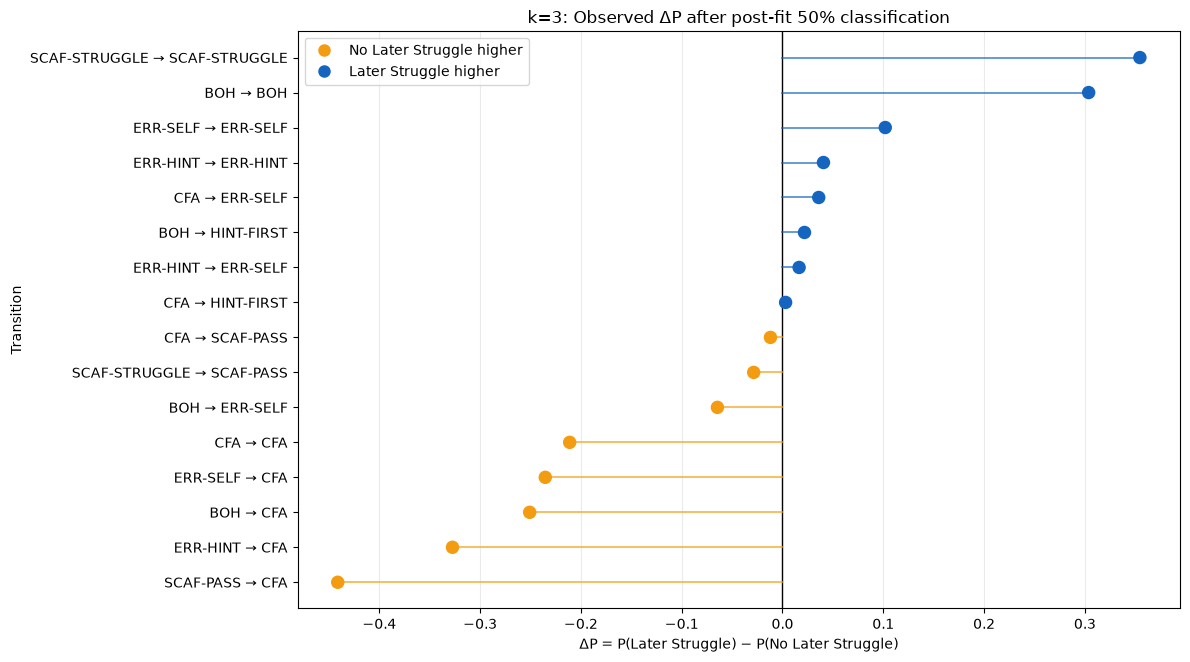

Transition-probability patterns plotted: 16


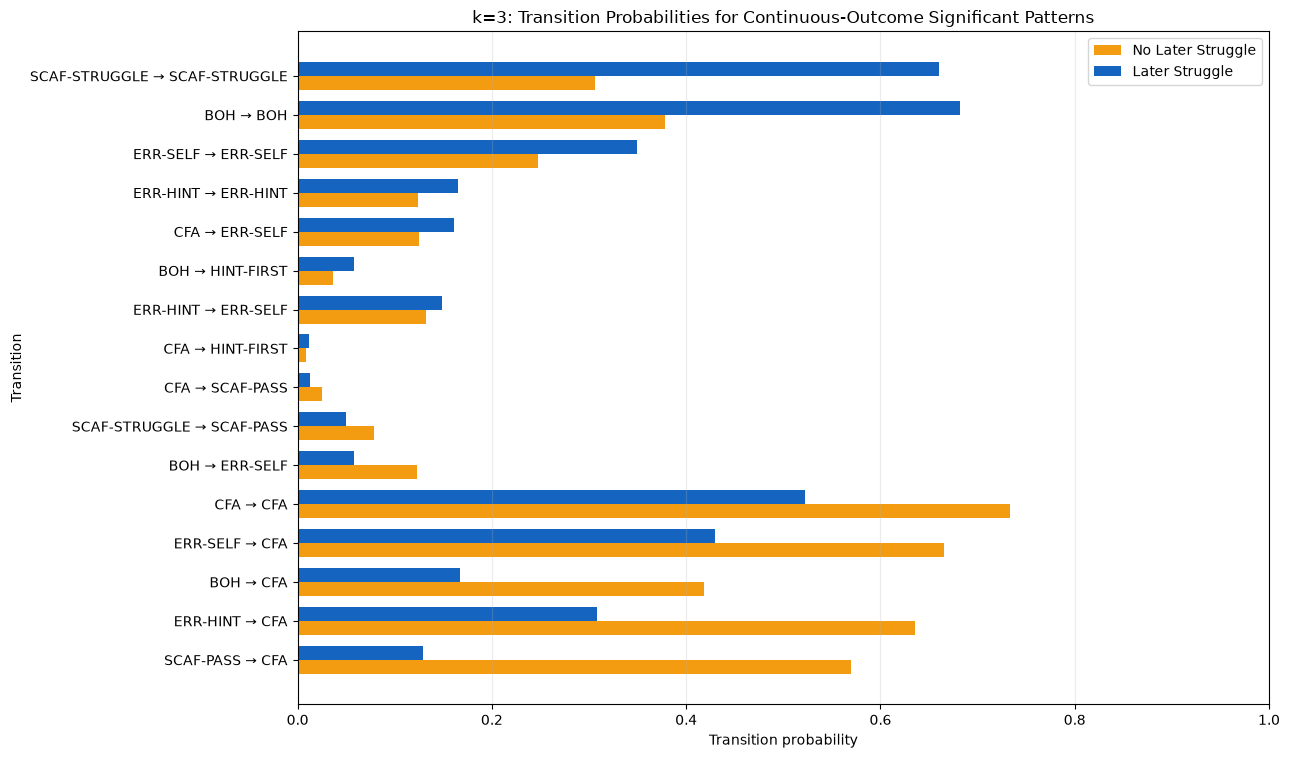

In [12]:
plot_pop_k3, plot_transitions_k3 = add_postfit_reporting_class(analysis_k3, transitions_k3)
delta_k3, tna0_k3, tna1_k3 = make_delta_from_plot_class(plot_transitions_k3)

model_sig_delta_k3 = plot_significant_delta(
    delta_k3,
    model_k3,
    "k=3: Observed ΔP after post-fit 50% classification",
    "k3_deltaP_significant_edges.png",
    model_label="Quade ANCOVA (continuous later % correct)"
)
bar_k3 = plot_transition_probability_bars(
    tna0_k3, tna1_k3, model_k3,
    "k=3: Transition Probabilities for Continuous-Outcome Significant Patterns",
    "k3_transition_probability_bars.png"
)


## 10. Select an optimum early-window k

The optimum early window is selected using the deterministic adjacent-window ARI criterion.

For each candidate `k = 3 ... 10`:

- the first `k` classified attempts form the early window;
- **at least the next `k` classified attempts** form the minimum later window;
- therefore eligibility requires `n_attempts >= 2k`;
- all attempts after the first `k` are retained for the later-struggle outcome;
- transition-direction ΔP matrices are compared between adjacent k values using ARI;
- the earliest k at maximum mean adjacent ARI across the Original and No-scaffolding populations is selected.

No regression p-values, FDR, bootstrap, or permutation results are used to select k.


In [13]:
NON_SCAFFOLD_STATES = ["CFA", "ERR-SELF", "BOH", "ERR-HINT", "HINT-FIRST"]
no_scaffold_episodes = episode.loc[
    episode["any_scaffold"].eq(0) & episode["state"].isin(NON_SCAFFOLD_STATES)
].copy()

scenario_episodes = {
    "Original": episode,
    "No scaffolding": no_scaffold_episodes
}

# ------------------------------------------------------------
# WINDOW SELECTION ONLY
# Each candidate needs k early + at least k later attempts.
# Therefore each history must have at least 2*k classified attempts.
# All attempts after the early window remain in the later outcome.
# ------------------------------------------------------------
window_deltas = {}
window_rows = []

for scenario, eps in scenario_episodes.items():
    max_len = int(eps.groupby(["userId", "skill"]).size().max())
    for k in range(K_MIN, min(K_MAX, max_len // 2) + 1):
        pop = build_population(eps, k, min_total_attempts=2 * k)
        d, _, _ = make_delta(pop["transitions"])
        window_deltas[(scenario, k)] = d
        window_rows.append({
            "Scenario": scenario,
            "Early problems": k,
            "Eligible histories": len(pop["population"]),
            "Later Struggle rate (%)": 100 * pop["population"]["later_struggle"].mean(),
            "Minimum later attempts": int(pop["population"]["n_later_attempts"].min()),
            "Max |ΔP|": float(np.nanmax(np.abs(d.to_numpy())))
        })

window_diag = pd.DataFrame(window_rows)
comparison = []
for scenario in scenario_episodes:
    ks = sorted(k for (s, k) in window_deltas if s == scenario)
    for k in ks:
        if k == min(ks):
            ari = np.nan
        else:
            a = window_deltas[(scenario, k - 1)].to_numpy().ravel()
            b = window_deltas[(scenario, k)].to_numpy().ravel()
            valid = np.isfinite(a) & np.isfinite(b)
            ari = adjusted_rand_score(np.sign(a[valid]), np.sign(b[valid])) if valid.any() else np.nan
        comparison.append({"Scenario": scenario, "Early problems": k, "ARI vs previous k": ari})

comparison = pd.DataFrame(comparison)
window_diag = window_diag.merge(comparison, on=["Scenario", "Early problems"], how="left")
selection = (window_diag.groupby("Early problems", as_index=False)
             .agg(mean_adjacent_ari=("ARI vs previous k", "mean"),
                  min_adjacent_ari=("ARI vs previous k", "min")))
selection_candidates = selection.dropna(subset=["mean_adjacent_ari"]).copy()
max_mean_ari = selection_candidates["mean_adjacent_ari"].max()
selected_k = int(selection_candidates.loc[
    selection_candidates["mean_adjacent_ari"] >= max_mean_ari - 1e-12,
    "Early problems"
].min())
selection["Selected"] = selection["Early problems"].eq(selected_k)

print("=" * 80)
print("OPTIMUM EARLY-WINDOW SELECTION")
print("=" * 80)
print("Criterion: earliest k at maximum mean adjacent-window ARI")
print("Window-selection eligibility: n_attempts >= 2*k (k early + at least k later)")
print("Later outcome: all classified attempts after the first k")
print("Maximum mean adjacent ARI:", round(max_mean_ari, 6))
print("Selected optimum k:", selected_k)
print("Final RQ1 minimum history:", 2 * selected_k)
print("Minimum later attempts:", selected_k)
print("=" * 80)
display(selection.round(4))
display(window_diag.sort_values(["Scenario", "Early problems"]).round(4))


OPTIMUM EARLY-WINDOW SELECTION
Criterion: earliest k at maximum mean adjacent-window ARI
Window-selection eligibility: n_attempts >= 2*k (k early + at least k later)
Later outcome: all classified attempts after the first k
Maximum mean adjacent ARI: 0.819193
Selected optimum k: 7
Final RQ1 minimum history: 14
Minimum later attempts: 7


,Early problems,mean_adjacent_ari,min_adjacent_ari,Selected
0,3,NaN,NaN,False
1,4,0.6581,0.4056,False
2,5,0.8175,0.6350,False
3,6,0.7297,0.6322,False
4,7,0.8192,0.7292,True
5,8,0.7427,0.5774,False
6,9,0.7161,0.6096,False
7,10,0.7102,0.5124,False


,Scenario,Early problems,Eligible histories,Later Struggle rate (%),Minimum later attempts,Max |ΔP|,ARI vs previous k
8,No scaffolding,3,9335,15.4580,3,0.3394,NaN
9,No scaffolding,4,6382,15.8414,4,0.2985,0.9107
10,No scaffolding,5,4695,18.1470,5,0.2895,1.0000
11,No scaffolding,6,3334,20.0660,6,0.3087,0.8272
12,No scaffolding,7,2505,22.7944,7,0.2967,0.9092
13,No scaffolding,8,1893,23.0322,8,0.3136,0.9080
14,No scaffolding,9,1453,25.1893,9,0.2940,0.8227
15,No scaffolding,10,1173,26.5132,10,0.2895,0.9080
0,Original,3,9980,17.9359,3,0.4412,NaN
1,Original,4,6985,18.4825,4,0.4213,0.4056


## 11. Refit the same Quade ANCOVA model at the optimum k

After selecting `k`, the same RQ1 population rule is used for the final Quade ANCOVA:

\[
N_{	ext{student}	imes	ext{skill}} \ge 2k.
\]

Thus:

- first `k` classified attempts = early window;
- at least the next `k` classified attempts = guaranteed later window;
- **all** attempts after the first `k` remain in the later window and contribute to later percent correct.

For example, if `k=5`, histories require at least 10 classified attempts, but a history with 12 attempts contributes all 7 later attempts (attempts 6–12) to the later outcome.


In [14]:
opt = build_population(episode, selected_k, min_total_attempts=2 * selected_k)
opt_population = opt["population"]
opt_transitions = opt["transitions"]
opt_counts = opt["transition_counts"]
opt_delta, opt_tna0, opt_tna1 = make_delta(opt_transitions)
opt_model, failures_opt, opt_model_frame = fit_quade_ancova_continuous(
    opt_population, opt_counts, selected_k
)

print("Optimum k:", selected_k)
print("Eligible histories:", len(opt_population))
print("Later percent correct — mean:", round(opt_population.later_percent_correct.mean(), 2))
print("Later percent correct — median:", round(opt_population.later_percent_correct.median(), 2))
print("Reporting-class later-struggle rate (<50%):", round(100 * (opt_population.later_percent_correct < 50).mean(), 2), "%")
print("Minimum history length:", int(opt_population.n_attempts.min()))
print("Minimum later attempts:", int(opt_population.n_later_attempts.min()))
assert opt_population.n_attempts.min() >= 2 * selected_k
assert opt_population.n_later_attempts.min() >= selected_k
print("FDR-significant Quade ANCOVA transitions:", int(opt_model.significant.sum()))
display(opt_model.round(5))
if failures_opt:
    display(pd.DataFrame(failures_opt))


Optimum k: 7
Eligible histories: 2830
Later percent correct — mean: 64.15
Later percent correct — median: 69.1
Reporting-class later-struggle rate (<50%): 25.51 %
Minimum history length: 14
Minimum later attempts: 7
FDR-significant Quade ANCOVA transitions: 10


,transition,adjusted_rank_effect,f_statistic,df_num,df_den,p_value,n,model_converged,fdr_p,significant,k,direction
0,SCAF-PASS → CFA,285.19505,21.41739,1.0,2780.0,0.00000,2830,True,0.00018,True,7,Higher later percent correct
1,ERR-SELF → CFA,118.44952,19.13798,1.0,2780.0,0.00001,2830,True,0.00030,True,7,Higher later percent correct
2,ERR-HINT → ERR-SELF,256.22816,15.43476,1.0,2780.0,0.00009,2830,True,0.00137,True,7,Higher later percent correct
3,ERR-SELF → ERR-SELF,134.12988,13.52623,1.0,2780.0,0.00024,2830,True,0.00282,True,7,Higher later percent correct
4,CFA → ERR-SELF,99.46218,12.95727,1.0,2780.0,0.00032,2830,True,0.00305,True,7,Higher later percent correct
5,CFA → SCAF-PASS,223.02232,12.26975,1.0,2780.0,0.00047,2830,True,0.00366,True,7,Higher later percent correct
6,BOH → BOH,-123.49850,10.22598,1.0,2780.0,0.00140,2830,True,0.00840,True,7,Lower later percent correct
7,BOH → HINT-FIRST,-212.67174,10.18789,1.0,2780.0,0.00143,2830,True,0.00840,True,7,Lower later percent correct
8,CFA → BOH,-104.16982,9.75209,1.0,2780.0,0.00181,2830,True,0.00945,True,7,Lower later percent correct
9,SCAF-STRUGGLE → SCAF-PASS,258.13544,6.77033,1.0,2780.0,0.00932,2830,True,0.04379,True,7,Higher later percent correct


,transition,error
0,HINT-FIRST → SCAF-STRUGGLE,ValueError('Transition has no variation.')
1,HINT-FIRST → SCAF-PASS,ValueError('Transition has no variation.')


## 12. SPM-style full length-`k` patterns at the optimum window

After the deterministic window-selection step, the same full-length sequence mining is repeated at the selected `k`.

This answers the descriptive SPM question using the **actual final early window**, while the next section continues with the existing Approach 3 Quade-type ANCOVA on the 49 length-2 transitions.

In [15]:
spm_opt = mine_spm_2_to_k(opt, selected_k)

print("=" * 80)
print(f"SPM — PATTERN LENGTHS 2 TO k={selected_k} — TEXTBOOK i-SUPPORT")
print("=" * 80)
print("Total candidate patterns:", len(spm_opt["all_patterns"]))
print("FDR-significant patterns:", int(spm_opt["significant_patterns"].shape[0]))
print("\nOnly FDR-significant differential patterns are reported:")
display(spm_opt["significant_patterns"].round(4))


SPM — PATTERN LENGTHS 2 TO k=7 — TEXTBOOK i-SUPPORT
Total candidate patterns: 5490
FDR-significant patterns: 12

Only FDR-significant differential patterns are reported:


,pattern_length,pattern,n_instances_NS,n_supporting_histories_NS,i_support_NS,s_support_NS,mean_i_support_per_history_NS,n_instances_S,n_supporting_histories_S,i_support_S,s_support_S,mean_i_support_per_history_S,mwu_U,p_value,n_histories_NS,n_histories_S,k,fdr_p,significant,direction
0,2,CFA → CFA,5275,1754,3.0074,1.0,3.0074,765,365,2.0959,1.0,2.0959,432506.5,0.0000,1754,365,7,0.0000,True,More instances in No Later Struggle
1,3,CFA → CFA → CFA,3072,1322,2.3238,1.0,2.3238,325,215,1.5116,1.0,1.5116,192421.0,0.0000,1322,215,7,0.0000,True,More instances in No Later Struggle
2,2,BOH → BOH,497,257,1.9339,1.0,1.9339,700,232,3.0172,1.0,3.0172,19571.5,0.0000,257,232,7,0.0000,True,More instances in Later Struggle
3,2,SCAF-STRUGGLE → SCAF-STRUGGLE,178,87,2.0460,1.0,2.0460,307,87,3.5287,1.0,3.5287,2104.5,0.0000,87,87,7,0.0000,True,More instances in Later Struggle
4,4,CFA → CFA → CFA → CFA,1694,776,2.1830,1.0,2.1830,109,69,1.5797,1.0,1.5797,34478.5,0.0000,776,69,7,0.0009,True,More instances in No Later Struggle
5,2,SCAF-PASS → SCAF-PASS,177,70,2.5286,1.0,2.5286,159,38,4.1842,1.0,4.1842,756.5,0.0001,70,38,7,0.0034,True,More instances in Later Struggle
6,3,SCAF-STRUGGLE → SCAF-STRUGGLE → SCAF-STRUGGLE,81,40,2.0250,1.0,2.0250,211,66,3.1970,1.0,3.1970,786.5,0.0003,40,66,7,0.0067,True,More instances in Later Struggle
7,3,SCAF-PASS → SCAF-PASS → SCAF-PASS,103,39,2.6410,1.0,2.6410,116,29,4.0000,1.0,4.0000,293.0,0.0004,39,29,7,0.0077,True,More instances in Later Struggle
8,5,CFA → CFA → CFA → CFA → CFA,918,483,1.9006,1.0,1.9006,40,29,1.3793,1.0,1.3793,9298.5,0.0015,483,29,7,0.0236,True,More instances in No Later Struggle
9,4,CFA → ERR-SELF → CFA → CFA,370,366,1.0109,1.0,1.0109,62,58,1.0690,1.0,1.0690,9998.0,0.0026,366,58,7,0.0371,True,More instances in Later Struggle


## 13. Optimum-k group-wise TNA


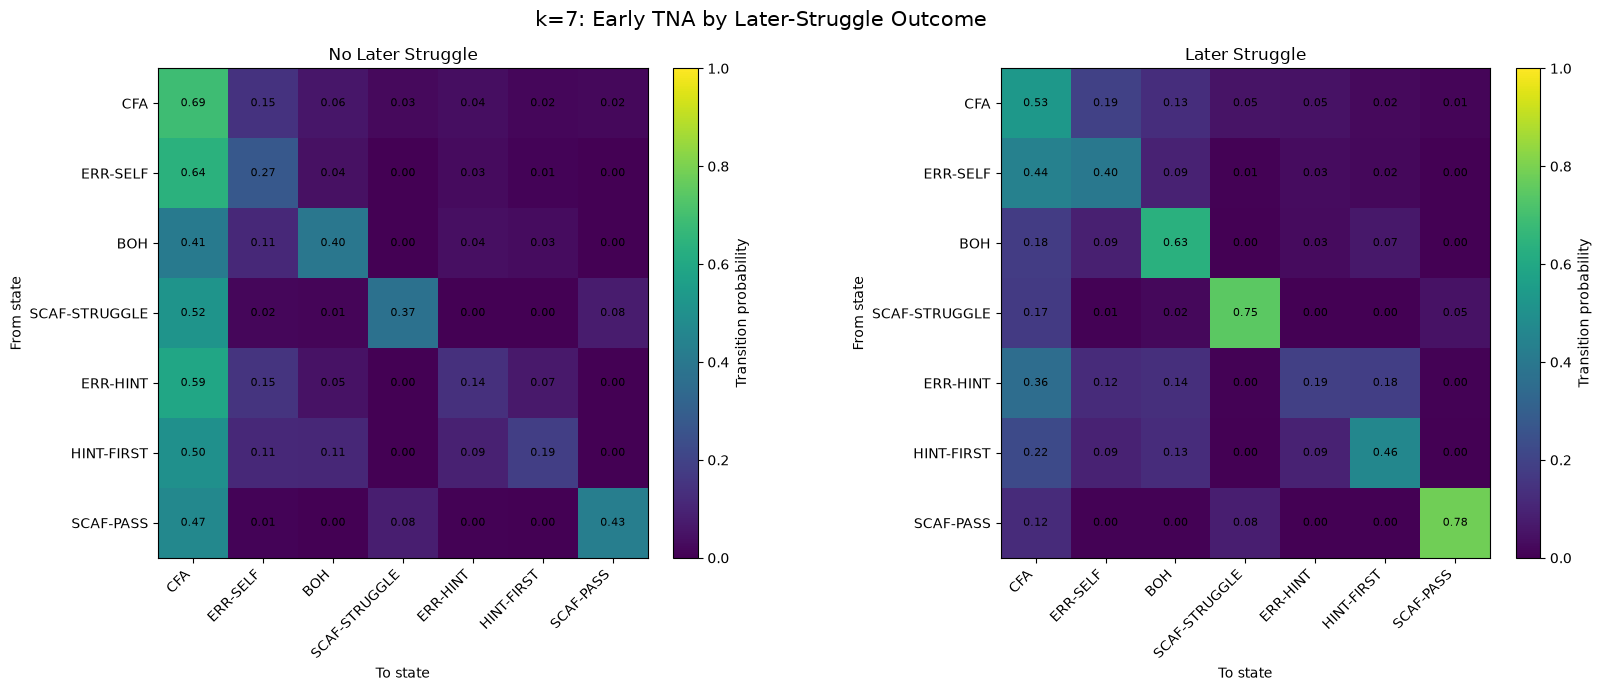

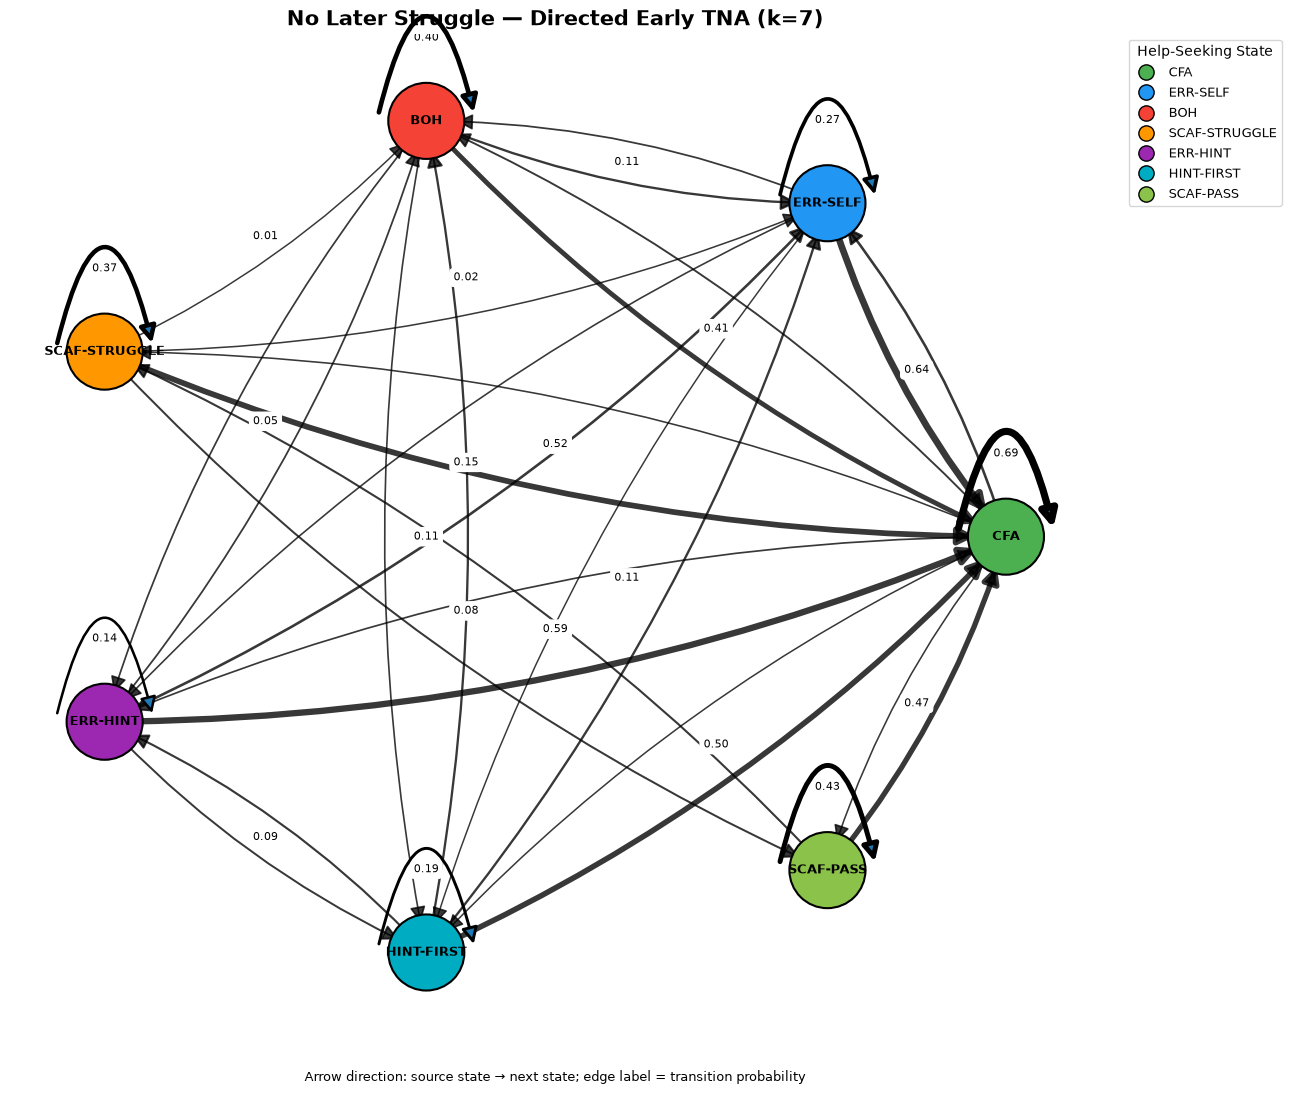

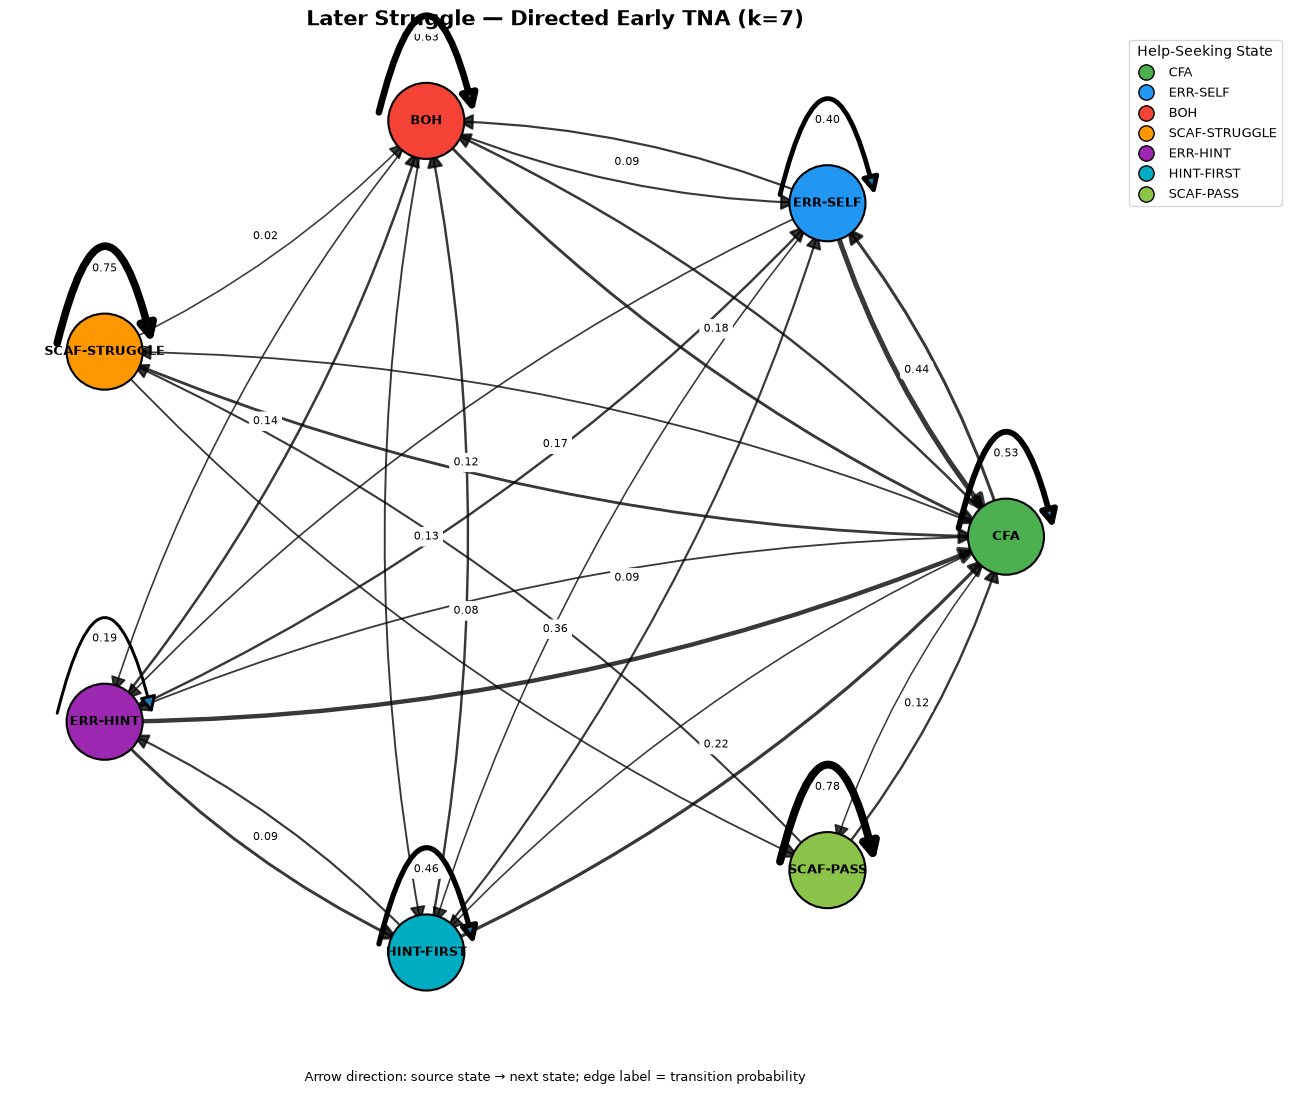

In [16]:
plot_pop_opt, plot_transitions_opt = add_postfit_reporting_class(opt_population, opt_transitions)
opt_delta, opt_tna0, opt_tna1 = make_delta_from_plot_class(plot_transitions_opt)

# ------------------------------------------------------------
# Optimum-k group-wise TNA heatmaps
# ------------------------------------------------------------
# opt_tna0 and opt_tna1 are produced by the optimum-k refit cell.

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 7)
)

for ax, outcome, mat in zip(
    axes,
    [0, 1],
    [opt_tna0, opt_tna1]
):
    im = ax.imshow(
        mat.to_numpy(),
        vmin=0,
        vmax=1
    )

    ax.set_title(
        OUTCOME_LABELS[outcome]
    )

    ax.set_xticks(
        range(len(STATE_ORDER)),
        STATE_ORDER,
        rotation=45,
        ha="right"
    )

    ax.set_yticks(
        range(len(STATE_ORDER)),
        STATE_ORDER
    )

    ax.set_xlabel("To state")
    ax.set_ylabel("From state")

    for i in range(len(STATE_ORDER)):
        for j in range(len(STATE_ORDER)):
            v = mat.iloc[i, j]

            if pd.notna(v):
                ax.text(
                    j,
                    i,
                    f"{v:.2f}",
                    ha="center",
                    va="center",
                    fontsize=8
                )

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label="Transition probability"
    )

fig.suptitle(
    f"k={selected_k}: Early TNA by Later-Struggle Outcome",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    PLOTS_DIR / f"k{selected_k}_tna_groupwise.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Optimum-k directed TNA network figures
# ------------------------------------------------------------
# These network views complement the probability heatmaps above.
# The arrowhead explicitly shows FROM state -> TO state.
G_opt_no_struggle = plot_single_tna_network(
    opt_tna0,
    outcome=0,
    selected_k=selected_k,
    threshold=0.01,
    filename=f"k{selected_k}_no_later_struggle_tna_network.png"
)

G_opt_struggle = plot_single_tna_network(
    opt_tna1,
    outcome=1,
    selected_k=selected_k,
    threshold=0.01,
    filename=f"k{selected_k}_later_struggle_tna_network.png"
)


### Directed TNA reading guide

The TNA network figures use **explicit arrowheads** for every directed transition. An arrow **A → B** means the learner moved from state A to state B in consecutive classified attempts. The edge label is the row-normalized transition probability. Self-transitions (for example, **BOH → BOH**) are drawn as curved self-loop arrows.

The heatmaps remain the numerical representation; the directed network is the visual representation of the same transition probabilities. The network does not change the underlying estimates or significance tests.

## 15. Optimum-k ΔP dot plot — Quade-type ANCOVA-significant edges only


Significant Quade ANCOVA (continuous later % correct) edges plotted: 10


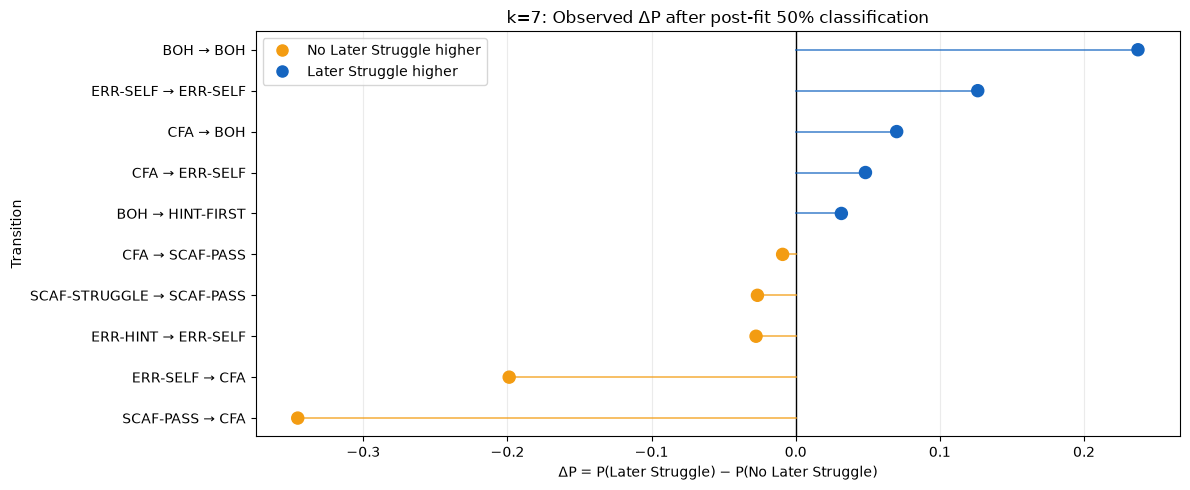

Transition-probability patterns plotted: 10


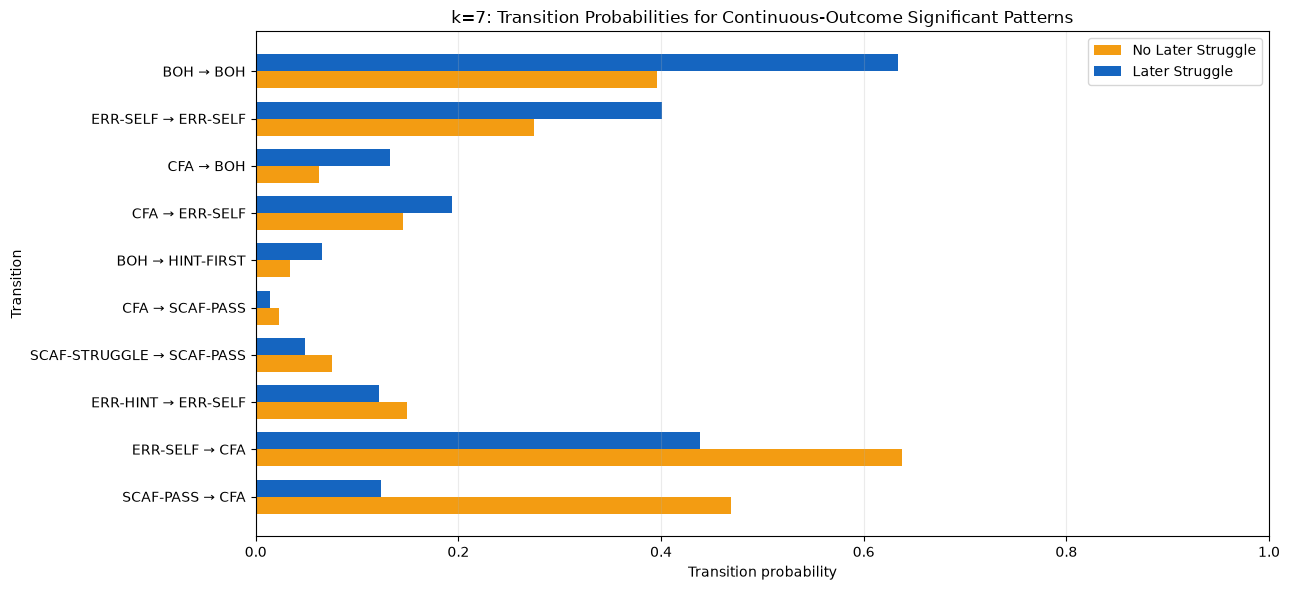

In [17]:
plot_pop_opt, plot_transitions_opt = add_postfit_reporting_class(opt_population, opt_transitions)
opt_delta, opt_tna0, opt_tna1 = make_delta_from_plot_class(plot_transitions_opt)

model_sig_delta_opt = plot_significant_delta(
    opt_delta,
    opt_model,
    f"k={selected_k}: Observed ΔP after post-fit 50% classification",
    f"k{selected_k}_deltaP_significant_edges.png",
    model_label="Quade ANCOVA (continuous later % correct)"
)
bar_opt = plot_transition_probability_bars(
    opt_tna0, opt_tna1, opt_model,
    f"k={selected_k}: Transition Probabilities for Continuous-Outcome Significant Patterns",
    f"k{selected_k}_transition_probability_bars.png"
)


## 16. Compare k=3 and optimum-k significant transition findings


In [18]:
k3_sig = model_k3.loc[
    model_k3["significant"],
    ["transition", "adjusted_rank_effect", "f_statistic", "p_value", "fdr_p"]
].copy()
k3_sig["k3_significant"] = True

opt_sig = opt_model.loc[
    opt_model["significant"],
    ["transition", "adjusted_rank_effect", "f_statistic", "p_value", "fdr_p"]
].copy()
opt_sig["opt_significant"] = True

comparison_k = k3_sig.merge(
    opt_sig,
    on="transition",
    how="outer",
    suffixes=("_k3", "_opt")
)
comparison_k["k3_significant"] = comparison_k["k3_significant"].fillna(False)
comparison_k["opt_significant"] = comparison_k["opt_significant"].fillna(False)
comparison_k["agreement"] = np.select(
    [
        comparison_k.k3_significant & comparison_k.opt_significant,
        comparison_k.k3_significant & ~comparison_k.opt_significant,
        ~comparison_k.k3_significant & comparison_k.opt_significant
    ],
    ["Significant at both k", "k=3 only", "Optimum k only"],
    default="Neither"
)

display(comparison_k.sort_values(["agreement", "transition"]).round(5))


,transition,adjusted_rank_effect_k3,f_statistic_k3,p_value_k3,fdr_p_k3,k3_significant,adjusted_rank_effect_opt,f_statistic_opt,p_value_opt,fdr_p_opt,opt_significant,agreement
4,CFA → BOH,NaN,NaN,NaN,NaN,False,-104.16982,9.75209,0.00181,0.00945,True,Optimum k only
0,BOH → BOH,-1235.99288,178.76435,0.00000,0.00000,True,-123.49850,10.22598,0.00140,0.00840,True,Significant at both k
3,BOH → HINT-FIRST,-972.71168,21.45880,0.00000,0.00002,True,-212.67174,10.18789,0.00143,0.00840,True,Significant at both k
6,CFA → ERR-SELF,838.97641,132.39204,0.00000,0.00000,True,99.46218,12.95727,0.00032,0.00305,True,Significant at both k
8,CFA → SCAF-PASS,983.42471,34.16028,0.00000,0.00000,True,223.02232,12.26975,0.00047,0.00366,True,Significant at both k
11,ERR-HINT → ERR-SELF,781.61305,12.95361,0.00032,0.00134,True,256.22816,15.43476,0.00009,0.00137,True,Significant at both k
12,ERR-SELF → CFA,680.82977,107.13659,0.00000,0.00000,True,118.44952,19.13798,0.00001,0.00030,True,Significant at both k
13,ERR-SELF → ERR-SELF,918.73993,70.62194,0.00000,0.00000,True,134.12988,13.52623,0.00024,0.00282,True,Significant at both k
14,SCAF-PASS → CFA,734.86351,26.57497,0.00000,0.00000,True,285.19505,21.41739,0.00000,0.00018,True,Significant at both k
15,SCAF-STRUGGLE → SCAF-PASS,753.43555,6.81932,0.00903,0.02770,True,258.13544,6.77033,0.00932,0.04379,True,Significant at both k


## 17. Export results

Exports include continuous-outcome Quade ANCOVA results, post-fit-class ΔP tables, SPM significant patterns for lengths 2…k, and window-selection diagnostics.

SPM exports contain only the FDR-significant differential patterns. No outcome × early-score stratified SPM table is produced; early score is used only as a covariate in the downstream Quade-type ANCOVA.


In [19]:
# Export Quade ANCOVA results, window diagnostics, significant-edge ΔP tables,
# and the generated TNA figures.

model_k3.to_csv(
    DATA_DIR / "RQ1_backup_quade_ancova_k3_results.csv",
    index=False
)

model_sig_delta_k3.to_csv(
    DATA_DIR / "RQ1_backup_quade_ancova_k3_significant_deltaP.csv",
    index=False
)

window_diag.to_csv(
    DATA_DIR / "RQ1_backup_quade_ancova_window_diagnostics.csv",
    index=False
)

selection.to_csv(
    DATA_DIR / "RQ1_backup_quade_ancova_window_selection.csv",
    index=False
)

opt_model.to_csv(
    DATA_DIR / "RQ1_backup_quade_ancova_optimum_k_results.csv",
    index=False
)

model_sig_delta_opt.to_csv(
    DATA_DIR / "RQ1_backup_quade_ancova_optimum_k_significant_deltaP.csv",
    index=False
)

comparison_k.to_csv(
    DATA_DIR / "RQ1_backup_quade_ancova_k3_vs_optimum.csv",
    index=False
)

print(
    "Exported Quade ANCOVA results, window diagnostics, "
    "significant-edge ΔP tables, and TNA figures to:",
    DATA_DIR
)


# Full length-k SPM descriptive outputs
spm_k3["significant_patterns"].to_csv(
    DATA_DIR / "RQ1_spm_k3_significant_patterns.csv", index=False
)
spm_opt["significant_patterns"].to_csv(
    DATA_DIR / "RQ1_spm_optimum_k_significant_patterns.csv", index=False
)
print("Exported SPM significant-pattern tables using textbook i-support.")


Exported Quade ANCOVA results, window diagnostics, significant-edge ΔP tables, and TNA figures to: c:\Users\Gaurish\Desktop\ET Folder IITB Synced\ET IITB\ET Sem 1\Learning Analytics\project\Code_Final_RQ1_to_be_used\rq1_merged_spm_quade_outputs
Exported SPM significant-pattern tables using textbook i-support.


## 17. RQ1 → RQ2/RQ3 frozen handoff export

This export is the bridge between the completed RQ1 analysis and the next research questions. It saves the objects needed to avoid rebuilding the frozen seven-state episode construction and RQ1 window definitions.

### Handoff contents

- `episode`: one row per student × skill × problem episode with the frozen seven-state label and episode-level action indicators.
- `k3_population`, `k3_transitions`, `k3_transition_counts`: baseline RQ1 objects.
- `opt_population`, `opt_transitions`, `opt_transition_counts`: final selected-window RQ1 objects.
- `opt_model`: final continuous-outcome Quade results.
- `window_selection`, `window_diagnostics`: deterministic k-selection evidence.
- `state_order`, `all_transitions`, `selected_k`: frozen analysis metadata.

The same handoff is used by both RQ2 and RQ3 starters.


In [21]:
import pickle

In [22]:
# ------------------------------------------------------------------
# Frozen RQ1 handoff for RQ2 and RQ3
# ------------------------------------------------------------------
HANDOFF_PATH = DATA_DIR / "rq1_objects_for_rq2_rq3.pkl"

rq1_handoff = {
    "episode": episode.copy(),
    "k3_population": analysis_k3.copy(),
    "k3_transitions": transitions_k3.copy(),
    "k3_transition_counts": counts_k3.copy(),
    "opt_population": opt_population.copy(),
    "opt_transitions": opt_transitions.copy(),
    "opt_transition_counts": opt_counts.copy(),
    "opt_model": opt_model.copy(),
    "window_selection": selection.copy(),
    "window_diagnostics": window_diag.copy(),
    "state_order": list(STATE_ORDER),
    "all_transitions": list(ALL_TRANSITIONS),
    "selected_k": int(selected_k),
    "alpha": float(ALPHA),
    "random_seed": int(RANDOM_SEED),
}

with open(HANDOFF_PATH, "wb") as f:
    pickle.dump(rq1_handoff, f, protocol=pickle.HIGHEST_PROTOCOL)

# Also export compact CSVs that are convenient for RQ2/RQ3 inspection.
opt_population.to_csv(DATA_DIR / "RQ1_handoff_opt_population.csv", index=False)
opt_transitions.to_csv(DATA_DIR / "RQ1_handoff_opt_transitions.csv", index=False)
opt_counts.to_csv(DATA_DIR / "RQ1_handoff_opt_transition_counts.csv", index=False)
analysis_k3.to_csv(DATA_DIR / "RQ1_handoff_k3_population.csv", index=False)
transitions_k3.to_csv(DATA_DIR / "RQ1_handoff_k3_transitions.csv", index=False)

print("Frozen RQ1 handoff:", HANDOFF_PATH)
print("Selected k:", selected_k)
print("Optimum histories:", len(opt_population))
print("Optimum transition rows:", len(opt_transitions))
print("Possible directed transitions:", len(ALL_TRANSITIONS))


Frozen RQ1 handoff: c:\Users\Gaurish\Desktop\ET Folder IITB Synced\ET IITB\ET Sem 1\Learning Analytics\project\Code_Final_RQ1_to_be_used\rq1_merged_spm_quade_outputs\rq1_objects_for_rq2_rq3.pkl
Selected k: 7
Optimum histories: 2830
Optimum transition rows: 16980
Possible directed transitions: 49


# RQ2 starter — Early → later transition-network change

**Research question:** How does the transition network change from the early window to the later window, and how does that change differ between Later-Struggle and No-Later-Struggle histories?

### Planned comparison

1. Load the frozen RQ1 handoff.
2. Reuse the frozen seven-state labels and selected `k`.
3. Construct **early transitions** from the first `k` classified attempts.
4. Construct **later transitions** from the attempts after `k`.
5. Build outcome-specific transition-probability matrices for Later Struggle and No Later Struggle.
6. Quantify early→later network change using a pre-specified network-distance/stability measure.
7. Compare the magnitude and direction of network change between the two outcome groups.

**Important:** This starter does not choose a final network-change metric for you. The final RQ2 notebook should pre-register the metric and whether it is computed on raw transition probabilities, normalized matrices, or another representation before testing group differences.


In [23]:
# ================================================================
# RQ2 STARTER CODE
# ================================================================
from pathlib import Path
import pickle
import numpy as np
import pandas as pd

HANDOFF_PATH = Path("rq1_merged_spm_quade_outputs/rq1_objects_for_rq2_rq3.pkl")

with open(HANDOFF_PATH, "rb") as f:
    handoff = pickle.load(f)

episode = handoff["episode"].copy()
population = handoff["opt_population"].copy()
selected_k = handoff["selected_k"]
STATE_ORDER = handoff["state_order"]
ALL_TRANSITIONS = handoff["all_transitions"]

print("Loaded RQ1 handoff.")
print("Selected k:", selected_k)
print("Histories:", len(population))

# ------------------------------------------------
# RQ2.1 Construct early and later transitions
# ------------------------------------------------
ep = episode.sort_values(
    ["userId", "skill", "start_time", "episode_row_order"],
    kind="mergesort"
).copy()

ep["skill_attempt"] = ep.groupby(["userId", "skill"]).cumcount() + 1
ep["outcome"] = ep.set_index(["userId", "skill"]).index.map(
    population.set_index(["userId", "skill"])["later_struggle"]
)

early = ep.loc[ep["skill_attempt"] <= selected_k].copy()
later = ep.loc[ep["skill_attempt"] > selected_k].copy()

def make_transition_table(frame):
    x = frame.sort_values(
        ["userId", "skill", "skill_attempt"],
        kind="mergesort"
    ).copy()
    x["next_state"] = x.groupby(["userId", "skill"])["state"].shift(-1)
    x = x.loc[x["next_state"].notna()].copy()
    x["transition"] = x["state"].astype(str) + " → " + x["next_state"].astype(str)
    return x

early_transitions = make_transition_table(early)
later_transitions = make_transition_table(later)

print("Early transitions:", len(early_transitions))
print("Later transitions:", len(later_transitions))

# ------------------------------------------------
# RQ2.2 Outcome-specific transition probabilities
# ------------------------------------------------
def transition_probability_matrix(transitions, outcome_value):
    sub = transitions.loc[transitions["outcome"] == outcome_value].copy()
    counts = pd.crosstab(sub["state"], sub["next_state"])
    counts = counts.reindex(index=STATE_ORDER, columns=STATE_ORDER, fill_value=0)
    row_totals = counts.sum(axis=1).replace(0, np.nan)
    return counts.div(row_totals, axis=0)

early_tna_NS = transition_probability_matrix(early_transitions, 0)
early_tna_S  = transition_probability_matrix(early_transitions, 1)
later_tna_NS = transition_probability_matrix(later_transitions, 0)
later_tna_S  = transition_probability_matrix(later_transitions, 1)

display(early_tna_NS.round(4))
display(early_tna_S.round(4))
display(later_tna_NS.round(4))
display(later_tna_S.round(4))

# ------------------------------------------------
# RQ2.3 STARTER: quantify early → later network change
# ------------------------------------------------
# TODO: Pre-specify the final network-change metric before inference.
# Examples to evaluate in the final RQ2 notebook:
#   - Frobenius distance between early and later probability matrices
#   - Jensen–Shannon distance after a clearly specified normalization
#   - edge-wise absolute change followed by a multiple-testing procedure
#
# Do not mix several metrics into the primary result after seeing which
# one produces the strongest group difference.

def frobenius_network_change(early_matrix, later_matrix):
    diff = later_matrix.fillna(0).to_numpy() - early_matrix.fillna(0).to_numpy()
    return float(np.sqrt(np.square(diff).sum()))

rq2_network_change = pd.DataFrame({
    "outcome_group": ["No Later Struggle", "Later Struggle"],
    "early_to_later_frobenius_change": [
        frobenius_network_change(early_tna_NS, later_tna_NS),
        frobenius_network_change(early_tna_S, later_tna_S),
    ],
})

display(rq2_network_change)
print("RQ2 starter complete: final inference/metric specification remains to be pre-specified.")


Loaded RQ1 handoff.
Selected k: 7
Histories: 2830
Early transitions: 80262
Later transitions: 50668


next_state,CFA,ERR-SELF,BOH,SCAF-STRUGGLE,ERR-HINT,HINT-FIRST,SCAF-PASS
state,,,,,,,
CFA,0.6894,0.1453,0.0623,0.0251,0.0378,0.0171,0.0230
ERR-SELF,0.6375,0.2746,0.0440,0.0036,0.0284,0.0109,0.0010
BOH,0.4104,0.1139,0.3960,0.0032,0.0414,0.0335,0.0016
SCAF-STRUGGLE,0.5188,0.0188,0.0126,0.3724,0.0021,0.0000,0.0753
ERR-HINT,0.5919,0.1489,0.0473,0.0018,0.1401,0.0701,0.0000
HINT-FIRST,0.5000,0.1134,0.1105,0.0000,0.0901,0.1860,0.0000
SCAF-PASS,0.4686,0.0097,0.0024,0.0845,0.0048,0.0024,0.4275


next_state,CFA,ERR-SELF,BOH,SCAF-STRUGGLE,ERR-HINT,HINT-FIRST,SCAF-PASS
state,,,,,,,
CFA,0.5331,0.1937,0.1324,0.0523,0.0502,0.0244,0.0139
ERR-SELF,0.4388,0.4009,0.0948,0.0058,0.0335,0.0233,0.0029
BOH,0.1792,0.0869,0.6335,0.0036,0.0290,0.0652,0.0027
SCAF-STRUGGLE,0.1707,0.0073,0.0220,0.7488,0.0000,0.0024,0.0488
ERR-HINT,0.3592,0.1214,0.1359,0.0049,0.1893,0.1845,0.0049
HINT-FIRST,0.2230,0.0941,0.1254,0.0000,0.0941,0.4634,0.0000
SCAF-PASS,0.1232,0.0049,0.0049,0.0837,0.0000,0.0000,0.7833


next_state,CFA,ERR-SELF,BOH,SCAF-STRUGGLE,ERR-HINT,HINT-FIRST,SCAF-PASS
state,,,,,,,
CFA,0.7806,0.1191,0.0425,0.0156,0.0202,0.0112,0.0108
ERR-SELF,0.7129,0.2166,0.0328,0.0063,0.0208,0.0093,0.0013
BOH,0.5960,0.1041,0.2325,0.0056,0.0362,0.0249,0.0006
SCAF-STRUGGLE,0.6847,0.0224,0.0168,0.2034,0.0056,0.0037,0.0634
ERR-HINT,0.6406,0.1366,0.0782,0.0040,0.0968,0.0438,0.0000
HINT-FIRST,0.5756,0.0840,0.0567,0.0084,0.0819,0.1912,0.0021
SCAF-PASS,0.6867,0.0120,0.0024,0.0627,0.0024,0.0024,0.2313


next_state,CFA,ERR-SELF,BOH,SCAF-STRUGGLE,ERR-HINT,HINT-FIRST,SCAF-PASS
state,,,,,,,
CFA,0.4477,0.2397,0.1486,0.0386,0.0671,0.0426,0.0156
ERR-SELF,0.3843,0.4414,0.1021,0.0056,0.0433,0.0229,0.0004
BOH,0.1897,0.1053,0.5983,0.0049,0.0354,0.0627,0.0036
SCAF-STRUGGLE,0.2014,0.0128,0.0163,0.6810,0.0023,0.0070,0.0792
ERR-HINT,0.3531,0.1778,0.1099,0.0037,0.2074,0.1481,0.0000
HINT-FIRST,0.1876,0.0709,0.1461,0.0061,0.0951,0.4935,0.0009
SCAF-PASS,0.1851,0.0043,0.0149,0.1404,0.0021,0.0043,0.6489


,outcome_group,early_to_later_frobenius_change
0,No Later Struggle,0.489026
1,Later Struggle,0.239722


RQ2 starter complete: final inference/metric specification remains to be pre-specified.


# RQ3 starter — Incremental predictive value of early transitions

**Research question:** Do early transition features add predictive value for later struggle beyond baseline correctness, assistance counts, BKT, and PFA?

### Planned nested-model logic

The core comparison should be **incremental prediction**, not simply whether transition coefficients are individually significant.

- **Baseline model:** early correctness / baseline correctness features.
- **+ Assistance:** add assistance-count features.
- **+ BKT:** add the pre-specified BKT knowledge estimate(s).
- **+ PFA:** add the pre-specified PFA feature(s).
- **+ Early transitions:** add the frozen 49 transition indicators/counts.

The final RQ3 analysis should compare the transition-augmented model against the strongest non-transition baseline using a pre-specified metric such as held-out log loss/AUC and an appropriate nested-model comparison where applicable.

**BKT and PFA are not fabricated here.** The starter code provides explicit placeholders for the user's finalized BKT/PFA outputs or implementations.


In [24]:
# ================================================================
# RQ3 STARTER CODE
# ================================================================
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.linear_model import LogisticRegression

HANDOFF_PATH = Path("rq1_merged_spm_quade_outputs/rq1_objects_for_rq2_rq3.pkl")

with open(HANDOFF_PATH, "rb") as f:
    handoff = pickle.load(f)

population = handoff["opt_population"].copy()
transition_counts = handoff["opt_transition_counts"].copy()
selected_k = handoff["selected_k"]
ALL_TRANSITIONS = handoff["all_transitions"]

# One row per student × skill history.
base = population[
    [
        "userId", "skill", "later_struggle",
        "early_score", "early_scaffold_share",
        "early_algebra_share", "early_choose_1_share",
        "early_fill_in_1_share", "mean_early_item_easiness"
    ]
].copy()

# Add early transition counts.
base = base.merge(
    transition_counts[["userId", "skill"] + ALL_TRANSITIONS],
    on=["userId", "skill"],
    how="left"
)

# ------------------------------------------------
# RQ3.1 Baseline predictors
# ------------------------------------------------
# This is the minimal baseline starter. Add the finalized
# correctness/assistance specification before the final run.
baseline_cols = [
    "early_score",
    "early_scaffold_share",
    "early_algebra_share",
    "early_choose_1_share",
    "early_fill_in_1_share",
    "mean_early_item_easiness",
]

X_base = base[baseline_cols].fillna(0).astype(float)
y = base["later_struggle"].astype(int)

# ------------------------------------------------
# RQ3.2 Assistance-count block
# ------------------------------------------------
# TODO: replace/add the exact assistance-count variables specified
# in the final RQ3 protocol. Keep these separate from the transition
# block so incremental value is identifiable.
assistance_cols = [
    # e.g. "early_hint_count", "early_bottom_hint_count",
    # "early_scaffold_count"
]

# ------------------------------------------------
# RQ3.3 BKT block
# ------------------------------------------------
# TODO: merge finalized BKT estimates at the same student × skill
# prediction unit. Example placeholder:
bkt_cols = [
    # "bkt_p_known_end_early"
]

# ------------------------------------------------
# RQ3.4 PFA block
# ------------------------------------------------
# TODO: merge finalized PFA features at the same prediction unit.
pfa_cols = [
    # "pfa_logit_early"
]

# ------------------------------------------------
# RQ3.5 Transition block
# ------------------------------------------------
transition_cols = ALL_TRANSITIONS

X_transition = base[transition_cols].fillna(0).astype(float)

# Example nested design matrices.
X0 = X_base.copy()
X1 = pd.concat([X0, base[[c for c in assistance_cols if c in base.columns]]], axis=1)
X2 = pd.concat([X1, base[[c for c in bkt_cols if c in base.columns]]], axis=1)
X3 = pd.concat([X2, base[[c for c in pfa_cols if c in base.columns]]], axis=1)
X4 = pd.concat([X3, X_transition], axis=1)

print("RQ3 prediction unit:", base[["userId", "skill"]].drop_duplicates().shape[0])
print("Selected k:", selected_k)
print("Baseline predictors:", list(X0.columns))
print("Transition predictors:", len(transition_cols))
print("BKT/PFA placeholders still require finalized variables:",
      bkt_cols, pfa_cols)

# ------------------------------------------------
# RQ3.6 Starter: grouped cross-validated comparison
# ------------------------------------------------
# IMPORTANT: choose the grouping unit and CV scheme before final inference.
# The example below groups by student to avoid placing histories from the
# same student in both train and test folds.
groups = base["userId"]

def cv_auc(model, X, y, groups, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    pred = cross_val_predict(
        model, X, y, cv=gkf, groups=groups, method="predict_proba"
    )[:, 1]
    return roc_auc_score(y, pred), log_loss(y, pred)

model = LogisticRegression(max_iter=2000, solver="liblinear")

auc0, ll0 = cv_auc(model, X0, y, groups)
auc4, ll4 = cv_auc(model, X4, y, groups)

comparison = pd.DataFrame({
    "model": ["baseline", "baseline_plus_early_transitions"],
    "AUC": [auc0, auc4],
    "log_loss": [ll0, ll4],
    "delta_AUC_vs_baseline": [0.0, auc4 - auc0],
    "delta_log_loss_vs_baseline": [0.0, ll4 - ll0],
})

display(comparison)

print(
    "RQ3 starter complete. Before final inference, finalize the assistance, "
    "BKT and PFA feature definitions and pre-specify the evaluation/comparison protocol."
)


RQ3 prediction unit: 2830
Selected k: 7
Baseline predictors: ['early_score', 'early_scaffold_share', 'early_algebra_share', 'early_choose_1_share', 'early_fill_in_1_share', 'mean_early_item_easiness']
Transition predictors: 49
BKT/PFA placeholders still require finalized variables: [] []


,model,AUC,log_loss,delta_AUC_vs_baseline,delta_log_loss_vs_baseline
0,baseline,0.774837,0.469762,0.000000,0.000000
1,baseline_plus_early_transitions,0.777644,0.468916,0.002806,-0.000846


RQ3 starter complete. Before final inference, finalize the assistance, BKT and PFA feature definitions and pre-specify the evaluation/comparison protocol.


## 18. Interpretation guardrails

### SPM and textbook i-support

- For every candidate pattern length `L = 2, 3, ..., k`, patterns are mined as **contiguous subsequences inside the first `k` early states**.
- The exact textbook definition is used:

\[
\boxed{\text{i-support} = \frac{\text{number of instances of pattern}}{\text{number of students/histories having the pattern}}}
\]

- `number of instances` is the total number of sliding-window occurrences across supporting histories.
- `number of students/histories having the pattern` is the number of distinct student × skill histories with at least one occurrence.
- Because pattern lengths are 2 through `k` while the early window is length `k`, a history can contain a pattern more than once when `L < k`; therefore i-support is **not forced to 1.0**.
- Differential sequence screening compares per-history occurrence counts between the two later-performance outcome groups using a two-sided Mann–Whitney U test, with BH-FDR across all candidate patterns.
- **SPM is not stratified by early score.** Early score is reserved for the downstream Quade-type ANCOVA covariate.
- **Only FDR-significant differential patterns are reported.**

### Quade-type ANCOVA

- The inferential outcome is **later percent correct**, calculated over all classified attempts after the first `k`.
- The 50% threshold is **not used in model fitting**.
- Continuous later percent correct and continuous nuisance variables are midranked. Exact equal percentage values may still legitimately produce tied average ranks; no artificial jitter is introduced.
- The binary later-performance class is created **after model fitting** solely for descriptive TNA, ΔP, and transition-probability plots.
- Positive adjusted rank effect means higher adjusted later percent correct; negative means lower adjusted later percent correct.
- BH-FDR is applied across the 49 transition-specific tests.
- ΔP remains descriptive: `P(Later Struggle) − P(No Later Struggle)` using the post-fit 50% reporting class.
- No permutation/bootstrap inference or logistic regression is used here.
- Eligibility remains `n_attempts >= 2k`, with all attempts after the first `k` contributing to later percent correct.
